# GA Log Analysis — LOOCV Sign Run
解析 `ga_run_optimized.log`，涵蓋 baseline / train / validation correlation 與 SNP 數統計。

**切換 run：只需修改第一個 code cell 的 `LOG_PATH`，然後 Kernel → Restart & Run All。**

In [1]:
import pandas as pd
import os
import re

base_path = r"D:\GA\Simu_Result"
flip_folders = {
    'Flip':   'SimuFlip_FlipGA',
    'Unflip': 'SimuFlip_NoFlipGA',
}

def get_category(id_r, sm_r, med_r, lg_r):
    ratios = {'small': sm_r, 'medium': med_r, 'large': lg_r}
    dominant_val = max(ratios.values())
    # 最大比例 < 0.5 視為 average（三者均衡）
    if dominant_val < 0.5:
        return 'average'
    dominant = max(ratios, key=ratios.get)
    return f"{dominant}_heavy"

records = []

for flip_label, flip_dir in flip_folders.items():
    flip_path = os.path.join(base_path, flip_dir)
    if not os.path.exists(flip_path):
        print(f"Not found: {flip_path}")
        continue

    for folder_name in os.listdir(flip_path):
        folder_path = os.path.join(flip_path, folder_name, 'Final_Simulation_Report.csv')
        if not os.path.isfile(folder_path):
            continue

        m = re.search(
            r'id([\d.]+)_sm([\d.]+)_med([\d.]+)_lg([\d.]+)_sfp([\d.]+)_S(\d+)',
            folder_name
        )
        if not m:
            print(f"Cannot parse: {folder_name}")
            continue

        id_r  = float(m.group(1))
        sm_r  = float(m.group(2))
        med_r = float(m.group(3))
        lg_r  = float(m.group(4))
        sfp   = float(m.group(5))
        n_s   = int(m.group(6))

        category = get_category(id_r, sm_r, med_r, lg_r)

        df = pd.read_csv(folder_path)
        df['Category']  = category
        df['Flip']      = flip_label
        df['N_samples'] = n_s
        df['sm_ratio']  = sm_r
        df['med_ratio'] = med_r
        df['lg_ratio']  = lg_r
        df['folder']    = folder_name
        records.append(df)
        print(f"OK: {flip_label} | {category} | S{n_s}")

combined = pd.concat(records, ignore_index=True)
combined.to_csv(r"D:\GA\Simu_Result\All_Simulation_Results.csv", index=False)
print(f"\nDone: {len(records)} files, {len(combined)} rows total")
print(f"\nCategories found: {sorted(combined['Category'].unique())}")
print(f"Sample sizes: {sorted(combined['N_samples'].unique())}")
print(f"Flip conditions: {combined['Flip'].unique()}")
print(f"\nRows per condition:")
print(combined.groupby(['Category','Flip','N_samples']).size().to_string())

OK: Flip | large_heavy | S100
OK: Flip | large_heavy | S150
OK: Flip | large_heavy | S200
OK: Flip | large_heavy | S250
OK: Flip | large_heavy | S50
OK: Flip | medium_heavy | S100
OK: Flip | medium_heavy | S150
OK: Flip | medium_heavy | S200
OK: Flip | medium_heavy | S250
OK: Flip | medium_heavy | S50
OK: Flip | average | S100
OK: Flip | average | S150
OK: Flip | average | S200
OK: Flip | average | S250
OK: Flip | average | S50
OK: Flip | small_heavy | S100
OK: Flip | small_heavy | S150
OK: Flip | small_heavy | S200
OK: Flip | small_heavy | S250
OK: Flip | small_heavy | S50
OK: Unflip | large_heavy | S100
OK: Unflip | large_heavy | S150
OK: Unflip | large_heavy | S200
OK: Unflip | large_heavy | S250
OK: Unflip | large_heavy | S50
OK: Unflip | medium_heavy | S100
OK: Unflip | medium_heavy | S150
OK: Unflip | medium_heavy | S200
OK: Unflip | medium_heavy | S250
OK: Unflip | medium_heavy | S50
OK: Unflip | average | S100
OK: Unflip | average | S150
OK: Unflip | average | S200
OK: Unflip |

In [1]:
import pandas as pd
import os
import re

base_path = r"D:\GA - 複製\Simulation\Simulation"
flip_folders = {
    'Flip':   'SimuFlip_FlipGA',
    'Unflip': 'SimuFlip_NoFlipGA',
}

# Name of the per-SNP detail file inside each condition folder.
# Change this if your actual filename differs.
SNP_DETAIL_FILENAME = 'Simulated_SNP_Details.csv'


def get_category(id_r, sm_r, med_r, lg_r):
    ratios = {'small': sm_r, 'medium': med_r, 'large': lg_r}
    dominant_val = max(ratios.values())
    # dominant ratio < 0.5 is treated as "average" (balanced across tiers)
    if dominant_val < 0.5:
        return 'average'
    dominant = max(ratios, key=ratios.get)
    return f"{dominant}_heavy"


records = []

for flip_label, flip_dir in flip_folders.items():
    flip_path = os.path.join(base_path, flip_dir)
    if not os.path.exists(flip_path):
        print(f"Not found: {flip_path}")
        continue

    for folder_name in os.listdir(flip_path):
        snp_file_path = os.path.join(flip_path, folder_name, SNP_DETAIL_FILENAME)
        if not os.path.isfile(snp_file_path):
            continue

        m = re.search(
            r'id([\d.]+)_sm([\d.]+)_med([\d.]+)_lg([\d.]+)_sfp([\d.]+)_S(\d+)',
            folder_name
        )
        if not m:
            print(f"Cannot parse: {folder_name}")
            continue

        id_r  = float(m.group(1))
        sm_r  = float(m.group(2))
        med_r = float(m.group(3))
        lg_r  = float(m.group(4))
        sfp   = float(m.group(5))
        n_s   = int(m.group(6))

        category = get_category(id_r, sm_r, med_r, lg_r)

        df = pd.read_csv(snp_file_path)
        df['Category']  = category
        df['Flip']      = flip_label
        df['N_samples'] = n_s
        df['sm_ratio']  = sm_r
        df['med_ratio'] = med_r
        df['lg_ratio']  = lg_r
        df['folder']    = folder_name
        records.append(df)
        print(f"OK: {flip_label} | {category} | S{n_s} | {len(df)} SNP rows")

combined = pd.concat(records, ignore_index=True)
combined.to_csv(r"D:\GA - 複製\All_SNP_Level_Results.csv", index=False)

print(f"\nDone: {len(records)} files, {len(combined)} SNP rows total")
print(f"\nCategories found: {sorted(combined['Category'].unique())}")
print(f"Sample sizes: {sorted(combined['N_samples'].unique())}")
print(f"Flip conditions: {combined['Flip'].unique()}")
print(f"\nRows per condition (gene-level file count check):")
print(combined.groupby(['Category', 'Flip', 'N_samples'])['Gene_ID'].nunique().to_string())
print(f"\nTotal SNP rows per condition:")
print(combined.groupby(['Category', 'Flip', 'N_samples']).size().to_string())

OK: Flip | large_heavy | S100 | 2505 SNP rows
OK: Flip | large_heavy | S150 | 2836 SNP rows
OK: Flip | large_heavy | S200 | 2558 SNP rows
OK: Flip | large_heavy | S250 | 2434 SNP rows
OK: Flip | large_heavy | S50 | 2553 SNP rows
OK: Flip | medium_heavy | S100 | 2121 SNP rows
OK: Flip | medium_heavy | S150 | 2676 SNP rows
OK: Flip | medium_heavy | S200 | 2296 SNP rows
OK: Flip | medium_heavy | S250 | 2506 SNP rows
OK: Flip | medium_heavy | S50 | 2814 SNP rows
OK: Flip | average | S100 | 2607 SNP rows
OK: Flip | average | S150 | 2573 SNP rows
OK: Flip | average | S200 | 2735 SNP rows
OK: Flip | average | S250 | 2618 SNP rows
OK: Flip | average | S50 | 2625 SNP rows
OK: Flip | small_heavy | S100 | 2487 SNP rows
OK: Flip | small_heavy | S150 | 2473 SNP rows
OK: Flip | small_heavy | S200 | 2502 SNP rows
OK: Flip | small_heavy | S250 | 2470 SNP rows
OK: Flip | small_heavy | S50 | 2418 SNP rows
OK: Unflip | large_heavy | S100 | 2505 SNP rows
OK: Unflip | large_heavy | S150 | 2836 SNP rows
OK:

In [7]:
# ── 切換要分析的 run：改這行，Kernel → Restart & Run All ────────────────────
from pathlib import Path

# # LOG_PATH = Path(r"D:\GA - 複製\5%_LOOCV_Flip\ga_run_optimized.log")
LOG_PATH = Path(r"D:\GA - 複製\LOOCV_Sign\ga_run_optimized.log")
LOG_PATH = Path(r"D:\GA - 複製\LOOCV_Unsign\ga_run_optimized.log")
# LOG_PATH = Path(r"D:\GA - 複製\5%_LOOCV_Unflip\ga_run_optimized.log")
# ─────────────────────────────────────────────────────────────────────────────

print(f"Analyzing : {LOG_PATH}")
print(f"Log size  : {LOG_PATH.stat().st_size/1e6:.2f} MB")

Analyzing : D:\GA - 複製\LOOCV_Unsign\ga_run_optimized.log
Log size  : 2.36 MB


## 圖表說明:GA 優化 vs. Baseline 驗證相關係數

**資料來源**:`All_Simulation_Results.csv`(4000 筆模擬結果)

### 欄位對應邏輯

| 圖表元素 | 對應欄位 / 篩選條件 |
|---|---|
| Baseline (PrediXcan) | `Corr_Before` |
| GA Optimized (Flip / Unflip) | `Corr_After`,依 `Flip` 欄位 (`Flip` / `Unflip`) 分組 |
| Small-Leading | `Category == 'small_heavy'` (sm_ratio=0.6) |
| Medium-Leading | `Category == 'medium_heavy'` (med_ratio=0.6) |
| Large-Leading | `Category == 'large_heavy'` (lg_ratio=0.6) |
| Average | `Category == 'average'` (三比例接近均等) |
| 樣本數 n | `N_samples` ∈ {50, 100, 150, 200, 250} |

### Panel A — 各組成情境的平均驗證相關係數
- 對每個 `Category` × `Flip` 分組計算 `Corr_Before`、`Corr_After` 的平均值
- 平均是「跨所有 5 個 n 值」計算的整體平均

### Panel B — 樣本數對驗證相關係數的影響(僅 Flip 條件)
- 先篩選 `Flip == 'Flip'`
- 再依 `Category` × `N_samples` 分組,計算 `Corr_After` 平均
- 觀察隨樣本數增加,四種情境的相關係數如何變化

> 💡 兩個 panel 用的分子完全來自同一份 CSV,只是 groupby 的維度與篩選條件不同(Panel A 跨 n 平均、只看 Flip vs Unflip;Panel B 保留 n 這個維度、只看 Flip)。

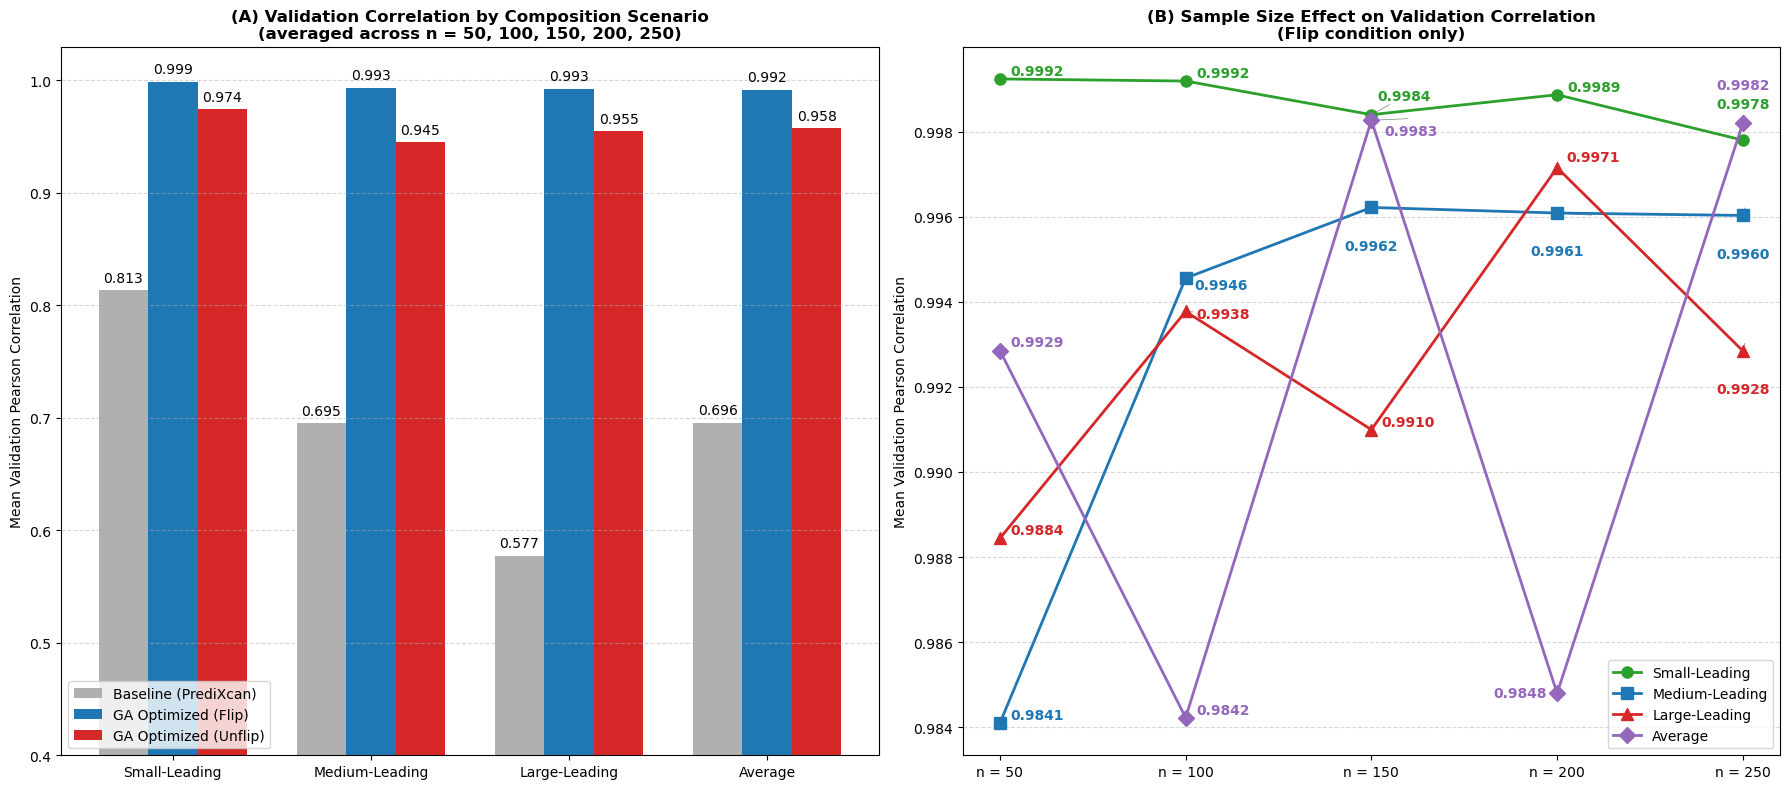

In [16]:
"""
Reproduce "Validation Correlation by Composition Scenario" (Panel A)
and "Sample Size Effect on Validation Correlation" (Panel B)
from All_Simulation_Results.csv

Usage:
    python plot_simulation_results.py
"""

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from adjustText import adjust_text

# ----------------------------------------------------------------------
# 1. Load data
# ----------------------------------------------------------------------
CSV_PATH = "D:\\GA\\Simu_Result\\All_Simulation_Results.csv"
df = pd.read_csv(CSV_PATH)

# Map internal category names -> display labels used in the figure
CATEGORY_LABELS = {
    "small_heavy": "Small-Leading",
    "medium_heavy": "Medium-Leading",
    "large_heavy": "Large-Leading",
    "average": "Average",
}
CATEGORY_ORDER = ["small_heavy", "medium_heavy", "large_heavy", "average"]

# ----------------------------------------------------------------------
# 2. Panel A data: mean correlation by scenario, averaged over all N_samples
#    Baseline      -> Corr_Before (same for Flip/Unflip, since it's PrediXcan baseline)
#    GA Optimized  -> Corr_After, split by Flip / Unflip
# ----------------------------------------------------------------------
panelA = (
    df.groupby(["Category", "Flip"])[["Corr_Before", "Corr_After"]]
    .mean()
    .reindex(CATEGORY_ORDER, level="Category")
)

baseline_vals = panelA.xs("Flip", level="Flip")["Corr_Before"].reindex(CATEGORY_ORDER)
flip_vals = panelA.xs("Flip", level="Flip")["Corr_After"].reindex(CATEGORY_ORDER)
unflip_vals = panelA.xs("Unflip", level="Flip")["Corr_After"].reindex(CATEGORY_ORDER)

# ----------------------------------------------------------------------
# 3. Panel B data: Flip condition only, mean Corr_After by Category x N_samples
# ----------------------------------------------------------------------
flip_df = df[df["Flip"] == "Flip"]
panelB = (
    flip_df.groupby(["Category", "N_samples"])["Corr_After"]
    .mean()
    .unstack("N_samples")
    .reindex(CATEGORY_ORDER)
)
n_samples_order = sorted(panelB.columns)
panelB = panelB[n_samples_order]

# ----------------------------------------------------------------------
# 4. Plot
# ----------------------------------------------------------------------
fig, (axA, axB) = plt.subplots(1, 2, figsize=(18, 8))

# ---- Panel A: grouped bar chart ----
x = np.arange(len(CATEGORY_ORDER))
bar_width = 0.25

bars_baseline = axA.bar(
    x - bar_width, baseline_vals.values, bar_width,
    label="Baseline (PrediXcan)", color="#B0B0B0"
)
bars_flip = axA.bar(
    x, flip_vals.values, bar_width,
    label="GA Optimized (Flip)", color="#1f77b4"
)
bars_unflip = axA.bar(
    x + bar_width, unflip_vals.values, bar_width,
    label="GA Optimized (Unflip)", color="#d62728"
)

# Value labels on top of each bar
for bars in (bars_baseline, bars_flip, bars_unflip):
    for b in bars:
        axA.text(
            b.get_x() + b.get_width() / 2, b.get_height() + 0.005,
            f"{b.get_height():.3f}", ha="center", va="bottom", fontsize=10
        )

axA.set_xticks(x)
axA.set_xticklabels([CATEGORY_LABELS[c] for c in CATEGORY_ORDER])
axA.set_ylim(0.4, 1.03)
axA.set_ylabel("Mean Validation Pearson Correlation")
axA.set_title(
    "(A) Validation Correlation by Composition Scenario\n"
    "(averaged across n = 50, 100, 150, 200, 250)",
    fontweight="bold"
)
axA.grid(axis="y", linestyle="--", alpha=0.5)
axA.legend(loc="lower left")

# ---- Panel B: line chart across sample sizes (Flip condition only) ----
line_colors = {
    "small_heavy": "#2ca02c",
    "medium_heavy": "#1f77b4",
    "large_heavy": "#d62728",
    "average": "#9467bd",
}
line_markers = {
    "small_heavy": "o",
    "medium_heavy": "s",
    "large_heavy": "^",
    "average": "D",
}

texts = []
lines = []
all_x, all_y = [], []
text_meta = []  # keep (category, n_samples) for each text, in the same order as `texts`

for cat in CATEGORY_ORDER:
    y = panelB.loc[cat].values
    line, = axB.plot(
        n_samples_order, y, marker=line_markers[cat],
        color=line_colors[cat], label=CATEGORY_LABELS[cat],
        linewidth=2, markersize=8
    )
    lines.append(line)

    for xi, yi in zip(n_samples_order, y):
        t = axB.text(xi, yi, f"{yi:.4f}", fontsize=10,
                      color=line_colors[cat], fontweight="bold")
        texts.append(t)
        all_x.append(xi)
        all_y.append(yi)
        text_meta.append((cat, xi))   # remember which point this text belongs to

adjust_text(texts, ax=axB, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

# ----------------------------------------------------------------------
# Step 1: relative nudges for points you're keeping from earlier adjustments
# (only the ones you did NOT ask to change this round)
# ----------------------------------------------------------------------
manual_nudge = {
    ("medium_heavy", 100): (0, -0.0004),
    ("average", 150): (-0.002, -0.0003),
}

for t, meta in zip(texts, text_meta):
    if meta in manual_nudge:
        cur_x, cur_y = t.get_position()
        dx, dy = manual_nudge[meta]
        t.set_position((cur_x + dx, cur_y + dy))

# ----------------------------------------------------------------------
# Step 2: absolute overrides for the points you asked to change this round
# ----------------------------------------------------------------------
gap_y = 0.0009  # vertical spacing unit, in data coordinates (tune this if too tight/loose)

manual_absolute = {
    # n=150 medium -> directly below its point
    ("medium_heavy", 150): (150, panelB.loc["medium_heavy", 150] - gap_y),

    # n=200 medium -> directly below its point
    ("medium_heavy", 200): (200, panelB.loc["medium_heavy", 200] - gap_y),
    # n=200 average -> to the left of its point, same height
    ("average", 200): (200 - 10, panelB.loc["average", 200]),

    # n=250 large & medium -> directly below their own points
    ("large_heavy", 250): (250, panelB.loc["large_heavy", 250] - gap_y),
    ("medium_heavy", 250): (250, panelB.loc["medium_heavy", 250] - gap_y),

    # n=250 small & average -> both stacked ABOVE the average point,
    # aligned to average's x position, offset so they don't overlap each other
    ("small_heavy", 250): (250, panelB.loc["average", 250] + gap_y * 0.5),
    ("average", 250): (250, panelB.loc["average", 250] + gap_y * 1.0),
}

for t, meta in zip(texts, text_meta):
    if meta in manual_absolute and manual_absolute[meta] is not None:
        t.set_position(manual_absolute[meta])

axB.set_xticks(n_samples_order)
axB.set_xticklabels([f"n = {n}" for n in n_samples_order])
axB.set_ylabel("Mean Validation Pearson Correlation")
axB.set_title(
    "(B) Sample Size Effect on Validation Correlation\n"
    "(Flip condition only)",
    fontweight="bold"
)
axB.grid(axis="y", linestyle="--", alpha=0.5)
axB.legend(loc="lower right")

plt.tight_layout()
plt.savefig("Simu_Corr_reproduced.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style='whitegrid', font_scale=1.1)

## 1. Log Parsing

In [9]:
# 各行的正規表達式
RE_BASELINE = re.compile(
    r'\[(?P<gene>ENSG\w+)\] baseline_corr=(?P<baseline>[\-\d.]+)'
    r' -> runs=(?P<runs>\d+), sign_flip=(?P<sign_flip>[^\s,]+)'
)
RE_TAS = re.compile(
    r'\[(?P<gene>ENSG\w+)\] TAS filter: (?P<snp_orig>\d+) → (?P<snp_tas>\d+) SNPs'
)
RE_ADAPTIVE = re.compile(
    r'\[(?P<gene>ENSG\w+)\] Adaptive scale=(?P<scale>[\d.]+): pop=(?P<pop>\d+)'
)
RE_RESULT = re.compile(
    r'\[\d+/\d+\] (?P<gene>ENSG\w+) \| Before: (?P<before>[\-\d.]+|N/A)'
    r' \| After: (?P<after>[\-\d.]+|N/A)'
    r' \| Train: (?P<train>[\-\d.]+|N/A)'
    r' \| Time:\s+(?P<time>[\d.]+)s'
)
RE_SKIP = re.compile(r'\[(?P<gene>ENSG\w+)\] Skipped:')

# 逐行解析
staging = {}   # gene -> dict (accumulate fields)
records = []

def _float(s):
    return None if s == 'N/A' else float(s)

with open(LOG_PATH, encoding='utf-8') as f:
    for line in f:
        m = RE_BASELINE.search(line)
        if m:
            g = m['gene']
            staging[g] = {
                'gene': g,
                'baseline_corr': float(m['baseline']),
                'runs': int(m['runs']),
                'sign_flip': m['sign_flip'].startswith('Yes'),
                'sign_flip_raw': m['sign_flip'],
            }
            continue
        m = RE_TAS.search(line)
        if m:
            g = m['gene']
            if g in staging:
                staging[g]['snp_orig'] = int(m['snp_orig'])
                staging[g]['snp_tas']  = int(m['snp_tas'])
            continue
        m = RE_ADAPTIVE.search(line)
        if m:
            g = m['gene']
            if g in staging:
                staging[g]['adaptive_scale'] = float(m['scale'])
                staging[g]['pop']            = int(m['pop'])
            continue
        m = RE_SKIP.search(line)
        if m:
            g = m['gene']
            rec = staging.pop(g, {'gene': g})
            rec.update({'skipped': True, 'before': None, 'after': None, 'train': None, 'time_s': 0})
            records.append(rec)
            continue
        m = RE_RESULT.search(line)
        if m:
            g = m['gene']
            rec = staging.pop(g, {'gene': g})
            rec.update({
                'skipped': False,
                'before' : _float(m['before']),
                'after'  : _float(m['after']),
                'train'  : _float(m['train']),
                'time_s' : float(m['time']),
            })
            records.append(rec)

df = pd.DataFrame(records)
# 衍生欄位
df['delta']      = df['after'] - df['before']           # GA 帶來的 LOOCV 變化量
df['train_gap']  = df['train'] - df['after']            # train - validation gap
df['abs_baseline'] = df['baseline_corr'].abs()

# 結果分類
def outcome(row):
    if row['skipped']: return 'Skipped'
    if pd.isna(row['after']): return 'Skipped'
    if row['after'] < -0.3:  return 'Neg_Strong'   # LOOCV <= -0.3
    if row['after'] < 0:     return 'Neg_Weak'      # -0.3 < LOOCV < 0
    if row['delta'] >= 0.1:  return 'Improved'
    if row['delta'] <= -0.1: return 'Worsened'
    return 'Neutral'

df['outcome'] = df.apply(outcome, axis=1)

print(f'Total records  : {len(df)}')
print(f'Skipped        : {df["skipped"].sum()}')
print(f'Valid (After≠NA): {df["after"].notna().sum()}')
df['outcome'].value_counts()

Total records  : 6986
Skipped        : 1102
Valid (After≠NA): 4782


outcome
Skipped       2204
Neutral       2201
Neg_Weak      1422
Improved       708
Worsened       298
Neg_Strong     153
Name: count, dtype: int64

## 2. 整體分布概覽

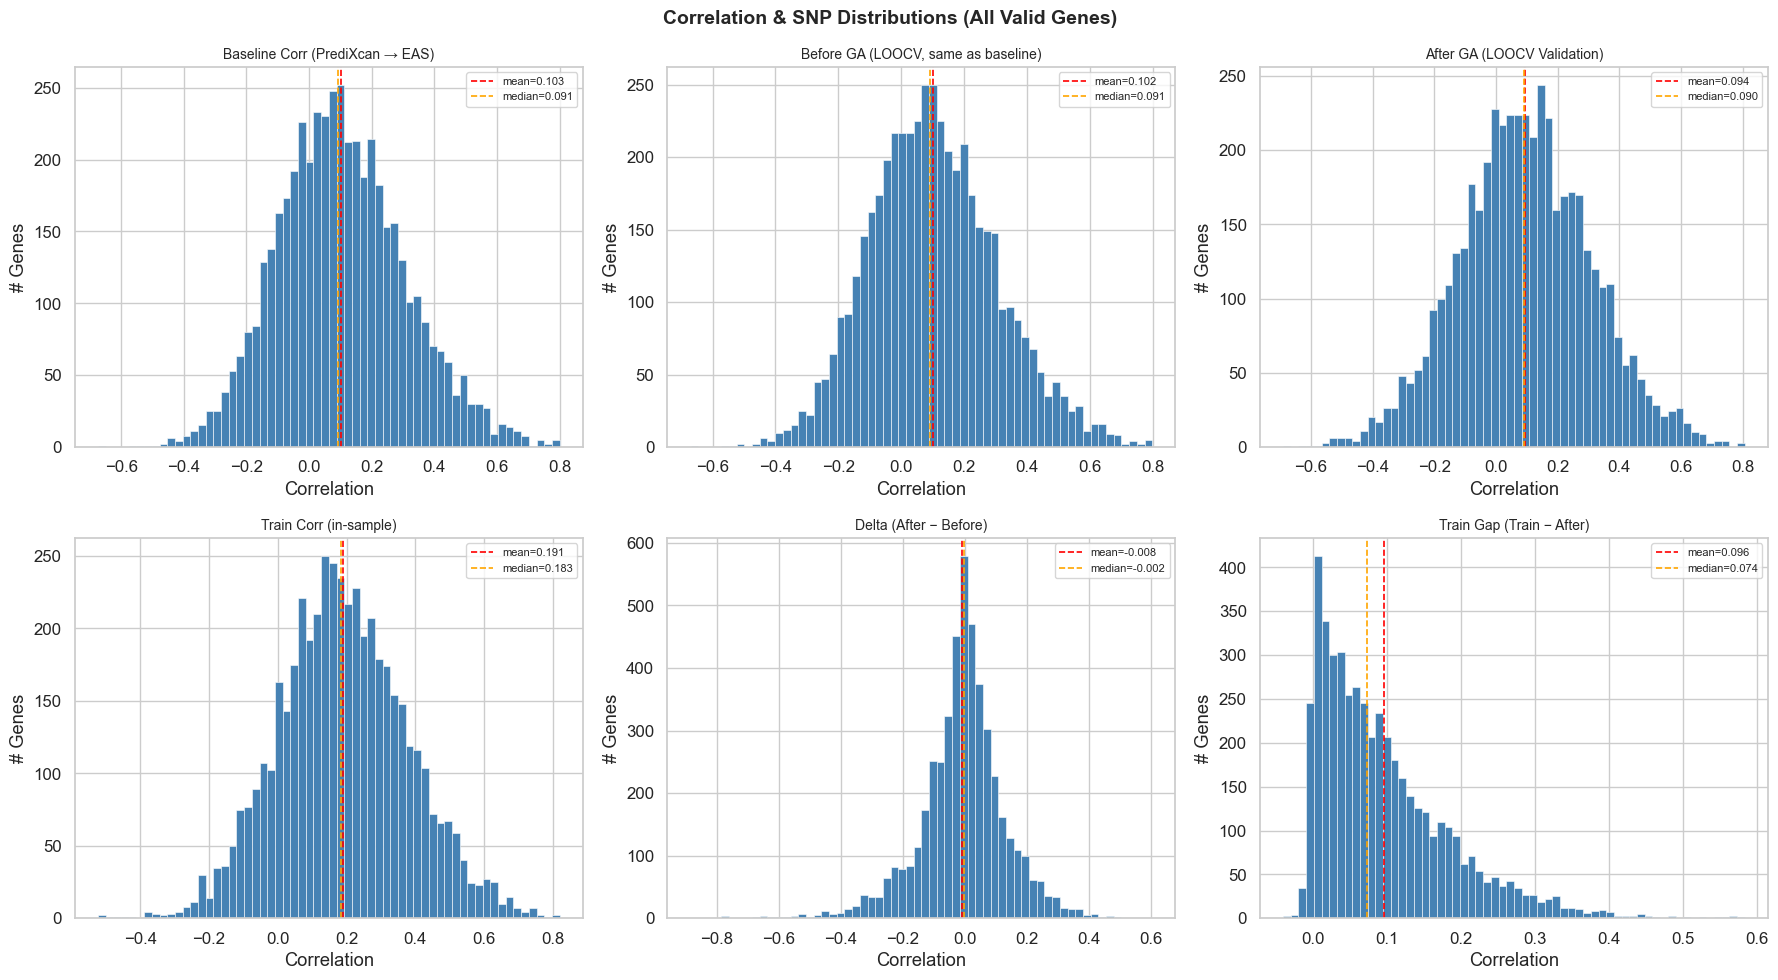

In [10]:
valid = df[df['after'].notna()].copy()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Correlation & SNP Distributions (All Valid Genes)', fontsize=14, fontweight='bold')

cols_titles = [
    ('baseline_corr', 'Baseline Corr (PrediXcan → EAS)'),
    ('before',        'Before GA (LOOCV, same as baseline)'),
    ('after',         'After GA (LOOCV Validation)'),
    ('train',         'Train Corr (in-sample)'),
    ('delta',         'Delta (After − Before)'),
    ('train_gap',     'Train Gap (Train − After)'),
]
for ax, (col, title) in zip(axes.flat, cols_titles):
    data = valid[col].dropna()
    ax.hist(data, bins=60, color='steelblue', edgecolor='white', linewidth=0.4)
    ax.axvline(data.mean(), color='red',    linestyle='--', linewidth=1.2, label=f'mean={data.mean():.3f}')
    ax.axvline(data.median(), color='orange', linestyle='--', linewidth=1.2, label=f'median={data.median():.3f}')
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
    ax.set_xlabel('Correlation')
    ax.set_ylabel('# Genes')

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_01_distributions.png', dpi=150)
plt.show()

## 1.5. Load final_summary.csv & Merge

合併 `final_summary.csv`（含 MAE、`weight_stability`、`train_corr_std`）到 `valid` DataFrame。  
後續所有 MAE / weight 分析皆使用 `df_merged`。

In [11]:
CSV_PATH = LOG_PATH.parent / 'final_summary.csv'
df_csv = pd.read_csv(CSV_PATH).rename(columns={
    'Correlation before GA': 'csv_before',
    'Correlation after GA':  'csv_after',
    'train_corr':            'csv_train',
})

df_merged = valid.merge(
    df_csv[['gene_id', 'weight_stability', 'weight_stability_penalty',
            'train_corr_std', 'MAE_PrediXcan_Real', 'MAE_GA_Real',
            'Improvement', 'Impact_Category', 'effective_runs']],
    left_on='gene', right_on='gene_id', how='left'
).drop(columns='gene_id')

# positive = GA improved over PrediXcan
df_merged['mae_delta'] = df_merged['MAE_PrediXcan_Real'] - df_merged['MAE_GA_Real']

print(f'Merged: {len(df_merged)} genes  |  CSV matched: {df_merged["MAE_GA_Real"].notna().sum()}')
print(df_merged['Impact_Category'].value_counts())

Merged: 4782 genes  |  CSV matched: 4782
Impact_Category
No Impact (-0.1~0.1)               3023
Worsened (< -0.1)                   925
Slight Improvement (0.1~0.3)        761
Moderate Improvement (0.3~0.6)       72
Significant Improvement (> 0.6)       1
Name: count, dtype: int64


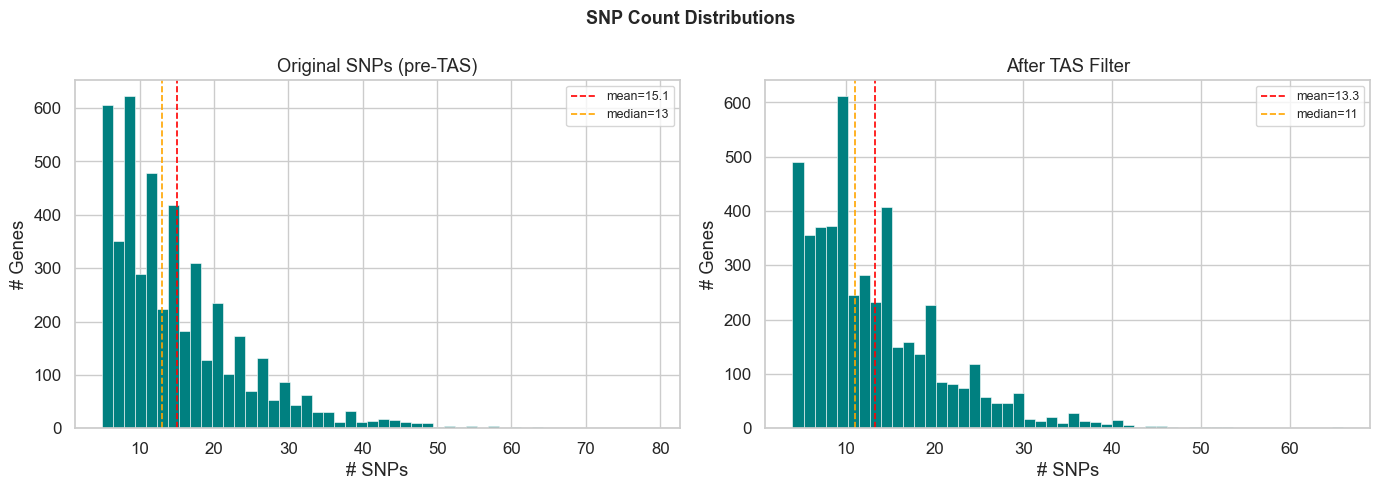

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('SNP Count Distributions', fontsize=13, fontweight='bold')

for ax, col, title in zip(axes, ['snp_orig', 'snp_tas'],
                           ['Original SNPs (pre-TAS)', 'After TAS Filter']):
    data = valid[col].dropna()
    ax.hist(data, bins=50, color='teal', edgecolor='white', linewidth=0.4)
    ax.axvline(data.mean(),   color='red',    linestyle='--', linewidth=1.2, label=f'mean={data.mean():.1f}')
    ax.axvline(data.median(), color='orange', linestyle='--', linewidth=1.2, label=f'median={data.median():.0f}')
    ax.set_title(title); ax.set_xlabel('# SNPs'); ax.set_ylabel('# Genes')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_02_snp_dist.png', dpi=150)
plt.show()

## 3. 描述統計表

In [13]:
summary_cols = ['baseline_corr', 'before', 'after', 'train', 'delta', 'train_gap', 'snp_orig', 'snp_tas', 'time_s']
mae_cols     = ['MAE_PrediXcan_Real', 'MAE_GA_Real', 'Improvement', 'weight_stability', 'train_corr_std']

print("=== Correlation & SNP Metrics ===")
display(valid[summary_cols].describe().round(3))

print("\n=== MAE & Stability Metrics (from final_summary.csv) ===")
display(df_merged[mae_cols].describe().round(4))

=== Correlation & SNP Metrics ===


,baseline_corr,before,after,train,delta,train_gap,snp_orig,snp_tas,time_s
count,4782.000,4782.000,4782.000,4782.000,4782.000,4782.000,4782.000,4782.000,4782.000
mean,0.103,0.102,0.094,0.191,-0.008,0.096,15.058,13.255,18.292
std,0.204,0.203,0.215,0.187,0.141,0.089,9.138,7.851,27.414
min,-0.674,-0.670,-0.690,-0.523,-0.884,-0.040,5.000,4.000,0.800
25%,-0.037,-0.038,-0.047,0.065,-0.076,0.027,8.000,7.000,4.300
50%,0.091,0.091,0.090,0.183,-0.002,0.074,13.000,11.000,8.100
75%,0.231,0.232,0.239,0.315,0.066,0.141,19.000,17.000,19.400
max,0.800,0.799,0.807,0.820,0.604,0.584,79.000,66.000,235.800



=== MAE & Stability Metrics (from final_summary.csv) ===


,MAE_PrediXcan_Real,MAE_GA_Real,Improvement,weight_stability,train_corr_std
count,4782.0000,4782.0000,4782.0000,4782.0000,4782.0000
mean,5.8310,9.7897,-0.0080,0.1387,0.0239
std,184.3882,364.9687,0.1411,0.1061,0.0048
min,0.5372,0.5063,-0.8840,0.0024,0.0072
25%,1.0309,1.0281,-0.0759,0.0612,0.0209
50%,1.1252,1.1284,-0.0019,0.1164,0.0238
75%,1.2103,1.2199,0.0659,0.1849,0.0265
max,10442.8359,22251.7129,0.6036,1.1156,0.0836


In [14]:
# Outcome 分類計數與比例
oc = valid['outcome'].value_counts()
oc_pct = (oc / len(valid) * 100).round(1)
pd.DataFrame({'Count': oc, 'Pct(%)': oc_pct})

,Count,Pct(%)
outcome,,
Neutral,2201,46.0
Neg_Weak,1422,29.7
Improved,708,14.8
Worsened,298,6.2
Neg_Strong,153,3.2


## 3b. R2 — Impact Category Distribution (MAE-based)

從 `final_summary.csv` 預計算的 `Impact_Category`，客觀描述 GA 在 MAE 改善上的分布比例。

,Gene Count,Percentage (%)
Impact_Category,,
Worsened (< -0.1),925,19.3
No Impact (-0.1~0.1),3023,63.2
Slight Improvement (0.1~0.3),761,15.9
Moderate Improvement (0.3~0.6),72,1.5
Significant Improvement (> 0.6),1,0.0


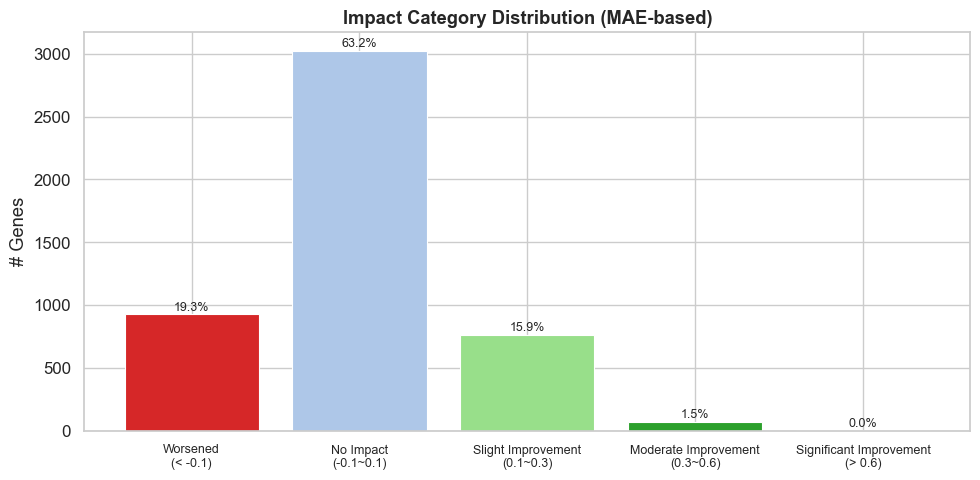

In [15]:
cat_order  = ['Worsened (< -0.1)', 'No Impact (-0.1~0.1)',
              'Slight Improvement (0.1~0.3)', 'Moderate Improvement (0.3~0.6)',
              'Significant Improvement (> 0.6)']
cat_colors = ['#d62728', '#aec7e8', '#98df8a', '#2ca02c', '#1a7a1a']

cat_counts = df_merged['Impact_Category'].value_counts().reindex(cat_order).fillna(0).astype(int)
cat_pct    = (cat_counts / cat_counts.sum() * 100).round(1)
cat_table  = pd.DataFrame({'Gene Count': cat_counts, 'Percentage (%)': cat_pct})
display(cat_table)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(range(len(cat_order)), cat_counts.values, color=cat_colors, edgecolor='white', linewidth=0.8)
ax.set_xticks(range(len(cat_order)))
ax.set_xticklabels([c.replace(' (', '\n(') for c in cat_order], fontsize=9)
ax.set_ylabel('# Genes')
ax.set_title('Impact Category Distribution (MAE-based)', fontweight='bold')
for bar, pct in zip(bars, cat_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
            f'{pct}%', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_R2_impact_category.png', dpi=150)
plt.show()

## 4. Before vs After Scatter (Signed Correlation)

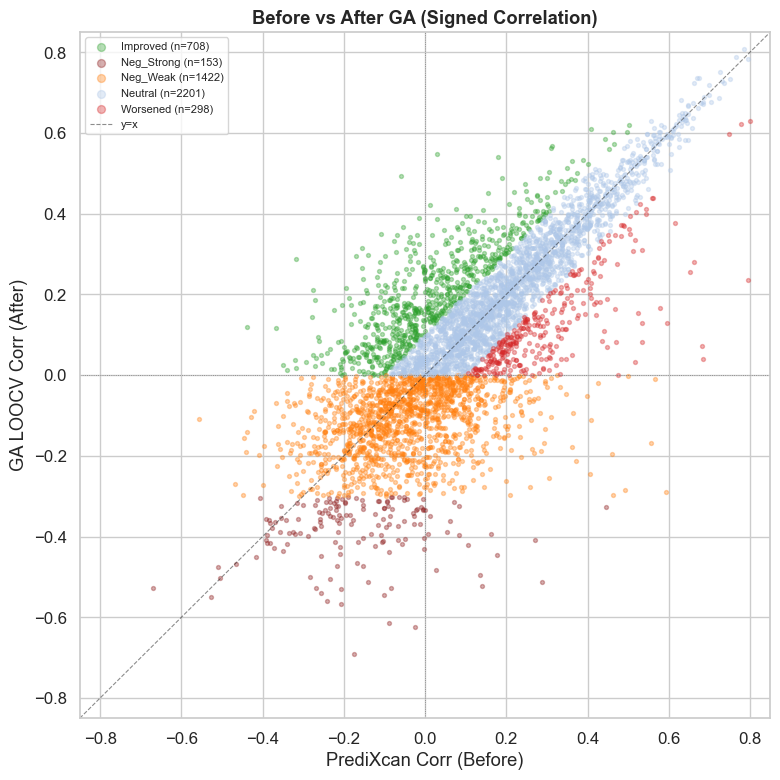

In [16]:
color_map = {
    'Improved':   '#2ca02c',
    'Neutral':    '#aec7e8',
    'Worsened':   '#d62728',
    'Neg_Weak':   '#ff7f0e',
    'Neg_Strong': '#8c1a1a',
}

fig, ax = plt.subplots(figsize=(8, 8))
for oc_name, grp in valid.groupby('outcome'):
    ax.scatter(grp['before'], grp['after'],
               alpha=0.35, s=8,
               color=color_map.get(oc_name, 'gray'),
               label=f'{oc_name} (n={len(grp)})', rasterized=True)

lim = 0.85
ax.plot([-lim, lim], [-lim, lim], 'k--', linewidth=0.8, alpha=0.5, label='y=x')
ax.axhline(0, color='gray', linewidth=0.6, linestyle=':')
ax.axvline(0, color='gray', linewidth=0.6, linestyle=':')
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel('PrediXcan Corr (Before)'); ax.set_ylabel('GA LOOCV Corr (After)')
ax.set_title('Before vs After GA (Signed Correlation)', fontweight='bold')
ax.legend(fontsize=8, markerscale=2)

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_03_scatter.png', dpi=150)
plt.show()

## 4b. R4 & R5 — MAE Comparison & Corr/MAE Concordance

C:\Users\wayne\AppData\Local\Temp\ipykernel_19464\3525581841.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([c.split('(')[0].strip() for c in cat_order], rotation=20, fontsize=9)
C:\Users\wayne\AppData\Local\Temp\ipykernel_19464\3525581841.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_merged[df_merged['Impact_Category'].notna()],
C:\Users\wayne\AppData\Local\Temp\ipykernel_19464\3525581841.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels([c.split('(')[0].strip() for c in cat_order], rotation=20, fontsize=9)


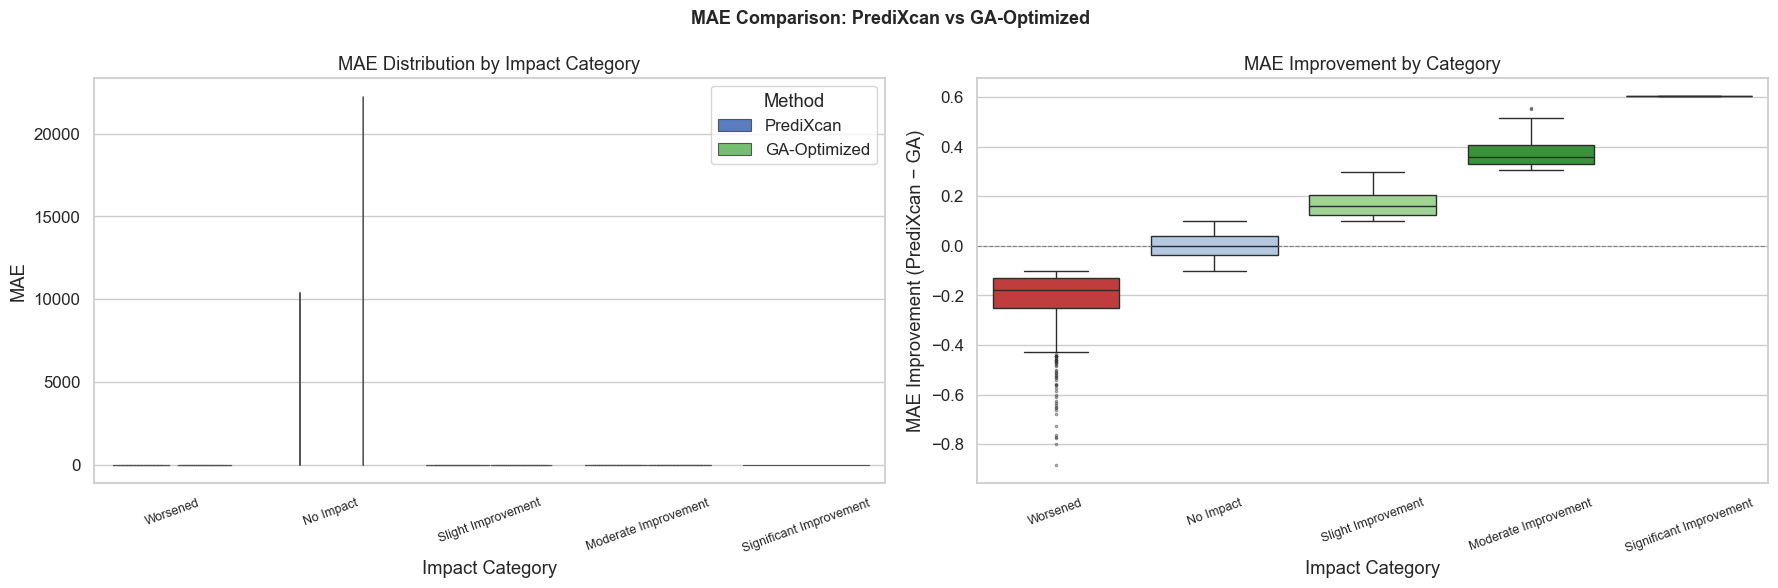

,n,mae_predixcan_mean,mae_ga_mean,improvement_mean,improvement_median
Impact_Category,,,,,
Worsened (< -0.1),925,1.0991,1.2353,-0.2106,-0.1785
No Impact (-0.1~0.1),3023,8.5585,14.8091,-0.0002,-0.0002
Slight Improvement (0.1~0.3),761,1.1867,1.0874,0.1707,0.1599
Moderate Improvement (0.3~0.6),72,1.2574,1.0414,0.3726,0.3573
Significant Improvement (> 0.6),1,1.3068,1.1291,0.6036,0.6036


In [17]:
# R4: MAE PrediXcan vs GA violin per Impact_Category + Improvement boxplot
cat_order  = ['Worsened (< -0.1)', 'No Impact (-0.1~0.1)',
              'Slight Improvement (0.1~0.3)', 'Moderate Improvement (0.3~0.6)',
              'Significant Improvement (> 0.6)']
cat_colors = ['#d62728', '#aec7e8', '#98df8a', '#2ca02c', '#1a7a1a']

mae_melt = df_merged[df_merged['Impact_Category'].notna()].melt(
    id_vars='Impact_Category',
    value_vars=['MAE_PrediXcan_Real', 'MAE_GA_Real'],
    var_name='Method', value_name='MAE'
)
mae_melt['Method'] = mae_melt['Method'].map({'MAE_PrediXcan_Real': 'PrediXcan', 'MAE_GA_Real': 'GA-Optimized'})

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('MAE Comparison: PrediXcan vs GA-Optimized', fontsize=13, fontweight='bold')

sns.violinplot(data=mae_melt, x='Impact_Category', y='MAE', hue='Method',
               palette={'PrediXcan': '#4878d0', 'GA-Optimized': '#6acc65'},
               ax=axes[0], inner='quartile', cut=0, linewidth=0.8, split=False,
               order=cat_order)
axes[0].set_xticklabels([c.split('(')[0].strip() for c in cat_order], rotation=20, fontsize=9)
axes[0].set_xlabel('Impact Category')
axes[0].set_ylabel('MAE')
axes[0].set_title('MAE Distribution by Impact Category')

sns.boxplot(data=df_merged[df_merged['Impact_Category'].notna()],
            x='Impact_Category', y='Improvement',
            palette=dict(zip(cat_order, cat_colors)), ax=axes[1],
            flierprops=dict(marker='.', markersize=3, alpha=0.5), order=cat_order)
axes[1].axhline(0, color='gray', linewidth=0.8, linestyle='--')
axes[1].set_xticklabels([c.split('(')[0].strip() for c in cat_order], rotation=20, fontsize=9)
axes[1].set_xlabel('Impact Category')
axes[1].set_ylabel('MAE Improvement (PrediXcan − GA)')
axes[1].set_title('MAE Improvement by Category')

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_R4_mae_comparison.png', dpi=150)
plt.show()

mae_summary = df_merged.groupby('Impact_Category', observed=True).agg(
    n=('MAE_GA_Real', 'size'),
    mae_predixcan_mean=('MAE_PrediXcan_Real', 'mean'),
    mae_ga_mean=('MAE_GA_Real', 'mean'),
    improvement_mean=('Improvement', 'mean'),
    improvement_median=('Improvement', 'median'),
).round(4).reindex(cat_order)
display(mae_summary)

Concordance rate (same direction): 99.6%


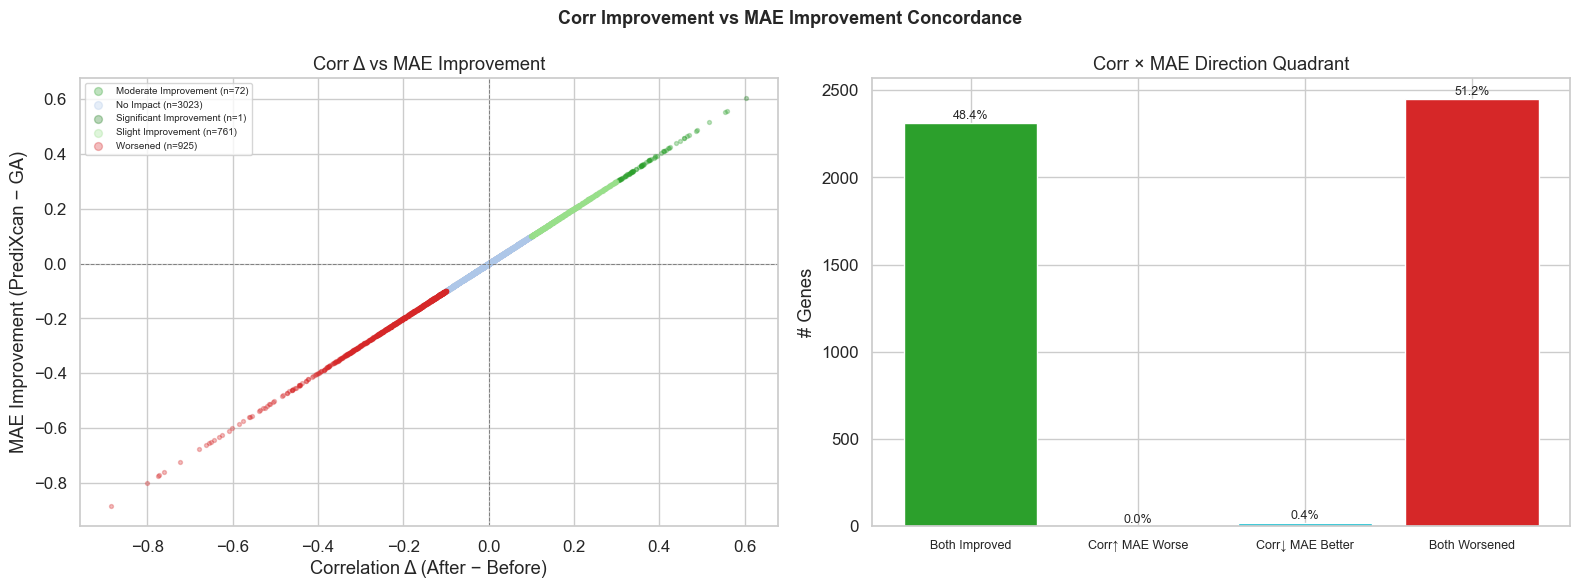

In [ ]:
# R5: Corr Δ vs MAE Improvement concordance scatter + quadrant analysis
cat_order  = ['Worsened (< -0.1)', 'No Impact (-0.1~0.1)',
              'Slight Improvement (0.1~0.3)', 'Moderate Improvement (0.3~0.6)',
              'Significant Improvement (> 0.6)']
cat_colors = ['#d62728', '#aec7e8', '#98df8a', '#2ca02c', '#1a7a1a']
cat_palette = dict(zip(cat_order, cat_colors))

m = df_merged.dropna(subset=['delta', 'Improvement', 'Impact_Category'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Corr Improvement vs MAE Improvement Concordance', fontsize=13, fontweight='bold')

for cat, grp in m.groupby('Impact_Category', observed=True):
    axes[0].scatter(grp['delta'], grp['Improvement'],
                    alpha=0.3, s=8, color=cat_palette.get(cat, 'gray'),
                    label=f'{cat.split("(")[0].strip()} (n={len(grp)})', rasterized=True)

                    
axes[0].axhline(0, color='gray', linewidth=0.7, linestyle='--')
axes[0].axvline(0, color='gray', linewidth=0.7, linestyle='--')
axes[0].set_xlabel('Correlation Δ (After − Before)')
axes[0].set_ylabel('MAE Improvement (PrediXcan − GA)')
axes[0].set_title('Corr Δ vs MAE Improvement')
axes[0].legend(fontsize=7, markerscale=2)

quad_labels = {(True, True): 'Both Improved', (True, False): 'Corr↑ MAE Worse',
               (False, True): 'Corr↓ MAE Better', (False, False): 'Both Worsened'}
quad_colors_map = {'Both Improved': '#2ca02c', 'Corr↑ MAE Worse': '#ff7f0e',
                   'Corr↓ MAE Better': '#17becf', 'Both Worsened': '#d62728'}
m2 = m.copy()
m2['quad'] = [quad_labels[(d > 0, i > 0)] for d, i in zip(m2['delta'], m2['Improvement'])]
q_order    = ['Both Improved', 'Corr↑ MAE Worse', 'Corr↓ MAE Better', 'Both Worsened']
q_counts   = m2['quad'].value_counts().reindex(q_order).fillna(0).astype(int)
q_pct      = (q_counts / q_counts.sum() * 100).round(1)
bars2 = axes[1].bar(range(len(q_counts)), q_counts.values,
                    color=[quad_colors_map[k] for k in q_counts.index], edgecolor='white')
axes[1].set_xticks(range(len(q_counts)))
axes[1].set_xticklabels(q_counts.index, fontsize=9)
axes[1].set_ylabel('# Genes')
axes[1].set_title('Corr × MAE Direction Quadrant')
for bar, pct in zip(bars2, q_pct.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'{pct}%', ha='center', va='bottom', fontsize=9)

concordance = m2['quad'].isin(['Both Improved', 'Both Worsened']).mean() * 100
print(f'Concordance rate (same direction): {concordance:.1f}%')
plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_R5_concordance.png', dpi=150)
plt.show()

## 5. Overfitting Diagnostic: Train vs LOOCV

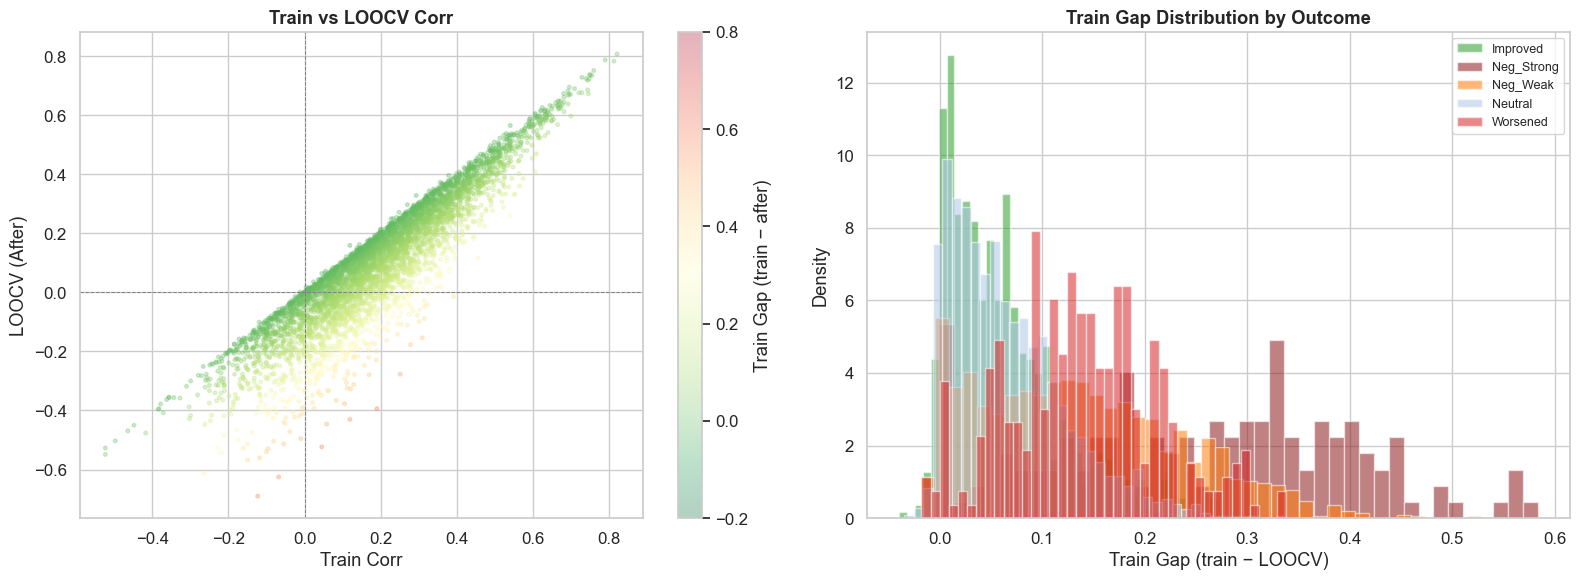

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 左：Train vs After scatter，以 train_gap 著色
sc = axes[0].scatter(valid['train'], valid['after'],
                     c=valid['train_gap'], cmap='RdYlGn_r',
                     vmin=-0.2, vmax=0.8, alpha=0.3, s=7, rasterized=True)
plt.colorbar(sc, ax=axes[0], label='Train Gap (train − after)')
axes[0].axhline(0, color='gray', linewidth=0.7, linestyle='--')
axes[0].axvline(0, color='gray', linewidth=0.7, linestyle='--')
axes[0].set_xlabel('Train Corr'); axes[0].set_ylabel('LOOCV (After)')
axes[0].set_title('Train vs LOOCV Corr', fontweight='bold')

# 右：Train Gap 分布，以 outcome 分組
for oc_name, grp in valid.groupby('outcome'):
    axes[1].hist(grp['train_gap'].dropna(), bins=40, alpha=0.55,
                 color=color_map.get(oc_name, 'gray'), label=oc_name, density=True)
axes[1].set_xlabel('Train Gap (train − LOOCV)')
axes[1].set_ylabel('Density')
axes[1].set_title('Train Gap Distribution by Outcome', fontweight='bold')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_04_overfit.png', dpi=150)
plt.show()

## 6. 顯著區間別分析 (After Corr Bins)

In [20]:
# 定義 After 的分析區間
after_bins   = [-1.01, -0.5, -0.3, -0.1, 0.0, 0.1, 0.3, 0.5, 1.01]
after_labels = ['<-0.5', '-0.5~-0.3', '-0.3~-0.1', '-0.1~0',
                '0~0.1', '0.1~0.3', '0.3~0.5', '>0.5']

valid['after_bin'] = pd.cut(valid['after'], bins=after_bins, labels=after_labels)

seg = valid.groupby('after_bin', observed=True).agg(
    n              = ('after',       'size'),
    baseline_mean  = ('baseline_corr','mean'),
    baseline_std   = ('baseline_corr','std'),
    before_mean    = ('before',       'mean'),
    after_mean     = ('after',        'mean'),
    train_mean     = ('train',        'mean'),
    train_gap_mean = ('train_gap',    'mean'),
    snp_tas_mean   = ('snp_tas',      'mean'),
    snp_tas_med    = ('snp_tas',      'median'),
    delta_mean     = ('delta',        'mean'),
    pct_sign_flip  = ('sign_flip',    'mean'),
).round(3)
seg['pct_sign_flip'] = (seg['pct_sign_flip'] * 100).round(1)
seg

,n,baseline_mean,baseline_std,before_mean,after_mean,train_mean,train_gap_mean,snp_tas_mean,snp_tas_med,delta_mean,pct_sign_flip
after_bin,,,,,,,,,,,
<-0.5,17,-0.195,0.232,-0.194,-0.550,-0.195,0.356,15.412,12.0,-0.356,0.0
-0.5~-0.3,138,-0.165,0.155,-0.165,-0.365,-0.123,0.242,12.413,11.0,-0.200,0.0
-0.3~-0.1,697,-0.078,0.148,-0.078,-0.179,-0.022,0.157,12.623,11.0,-0.101,0.0
-0.1~0,728,-0.007,0.129,-0.007,-0.047,0.071,0.117,12.867,11.0,-0.040,0.0
0~0.1,908,0.049,0.127,0.049,0.051,0.145,0.094,12.612,10.5,0.003,0.0
0.1~0.3,1494,0.155,0.128,0.154,0.193,0.262,0.069,13.272,11.0,0.039,0.0
0.3~0.5,645,0.332,0.122,0.331,0.379,0.430,0.051,14.792,13.0,0.047,0.0
>0.5,155,0.565,0.110,0.564,0.589,0.620,0.031,15.626,14.0,0.024,0.0


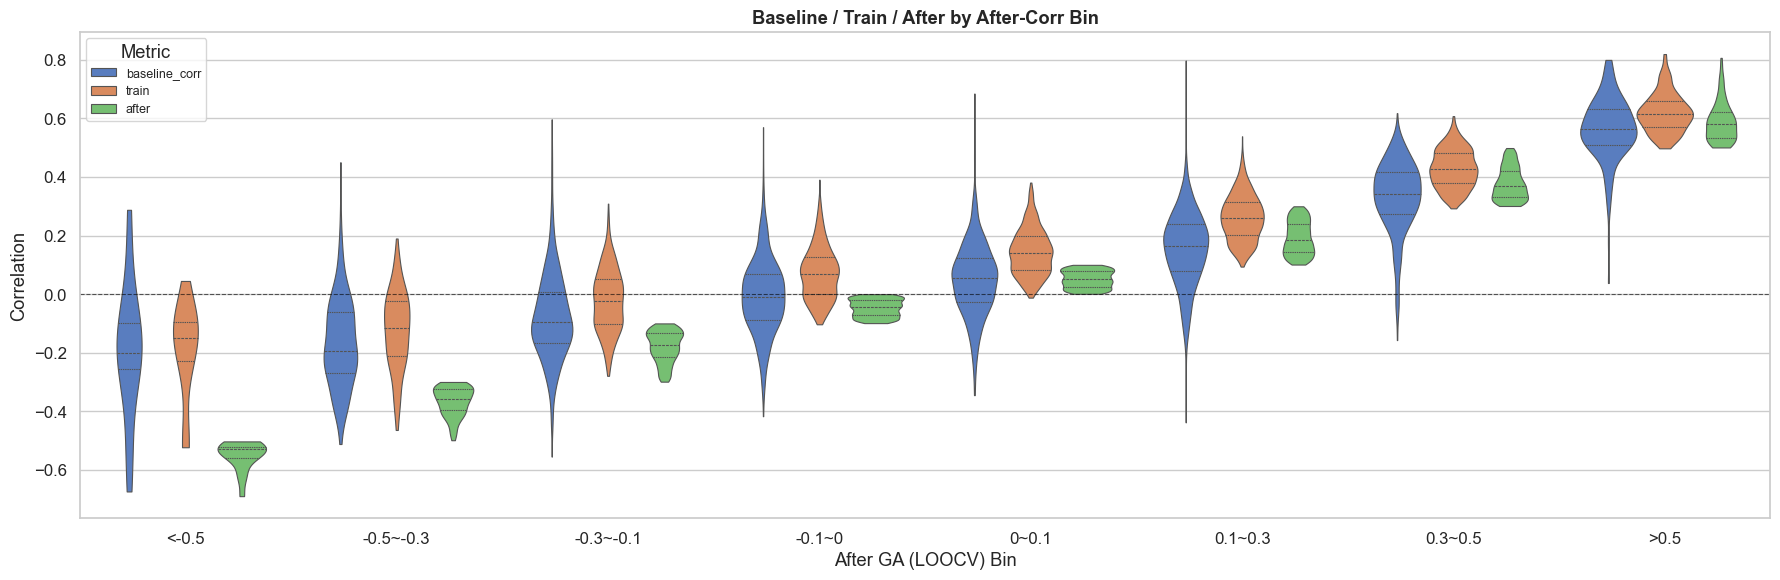

In [21]:
# 各區間 baseline / train / after 的 violin plot
plot_df = valid[['after_bin', 'baseline_corr', 'train', 'after']].melt(
    id_vars='after_bin', var_name='Metric', value_name='Corr'
).dropna()

fig, ax = plt.subplots(figsize=(18, 6))
palette = {'baseline_corr': '#4878d0', 'train': '#ee854a', 'after': '#6acc65'}
sns.violinplot(data=plot_df, x='after_bin', y='Corr', hue='Metric',
               palette=palette, ax=ax, inner='quartile',
               split=False, linewidth=0.8, cut=0)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.6)
ax.set_xlabel('After GA (LOOCV) Bin')
ax.set_ylabel('Correlation')
ax.set_title('Baseline / Train / After by After-Corr Bin', fontweight='bold')
ax.legend(title='Metric', fontsize=9)

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_05_violin_bins.png', dpi=150)
plt.show()

C:\Users\wayne\AppData\Local\Temp\ipykernel_19464\3320755128.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=valid.dropna(subset=['snp_tas']),


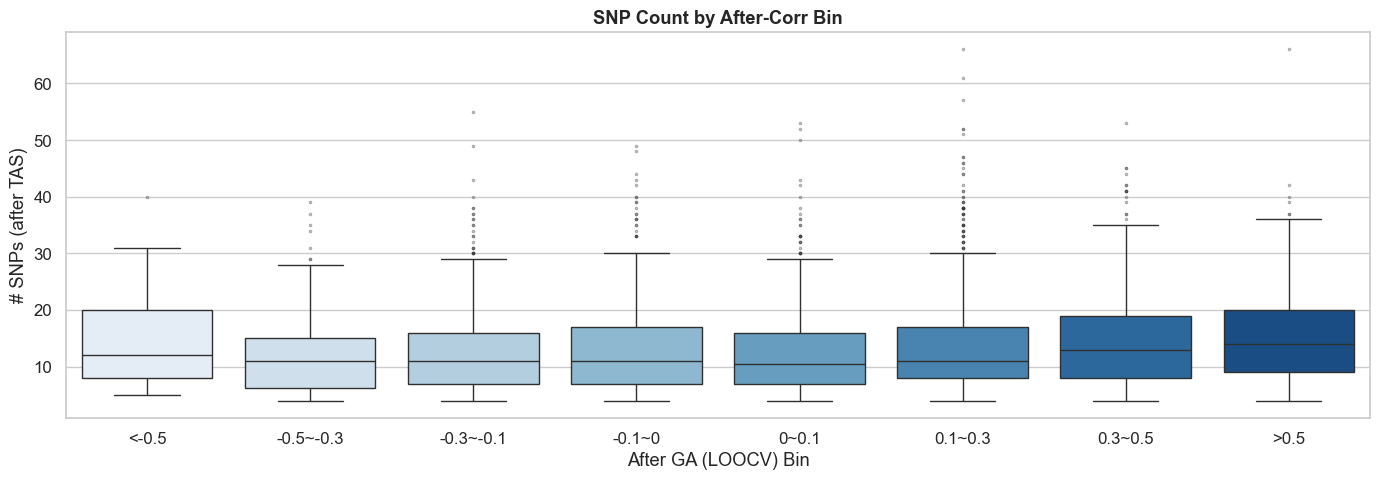

In [22]:
# 各區間 SNP 數 (TAS) boxplot
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=valid.dropna(subset=['snp_tas']),
            x='after_bin', y='snp_tas', ax=ax,
            palette='Blues', flierprops=dict(marker='.', markersize=3, alpha=0.4))
ax.set_xlabel('After GA (LOOCV) Bin')
ax.set_ylabel('# SNPs (after TAS)')
ax.set_title('SNP Count by After-Corr Bin', fontweight='bold')

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_06_snp_bins.png', dpi=150)
plt.show()

## 7. 問題基因深挖：After ≤ -0.3

In [23]:
neg = valid[valid['after'] <= -0.3].copy()
print(f'Genes with After ≤ -0.3 : {len(neg)}')

# Before 分群
b_bins   = [-1.01, -0.3, -0.1, 0.0, 0.1, 0.3, 1.01]
b_labels = ['<-0.3', '-0.3~-0.1', '-0.1~0', '0~0.1', '0.1~0.3', '>0.3']
neg['before_bin'] = pd.cut(neg['before'], bins=b_bins, labels=b_labels)

# Train 分群
t_bins   = [-1.01, 0.0, 0.2, 0.4, 0.6, 1.01]
t_labels = ['<0', '0~0.2', '0.2~0.4', '0.4~0.6', '>0.6']
neg['train_bin'] = pd.cut(neg['train'], bins=t_bins, labels=t_labels)

print('\n--- Before 分群 ---')
print(neg['before_bin'].value_counts().reindex(b_labels))
print('\n--- Train 分群 ---')
print(neg['train_bin'].value_counts().reindex(t_labels))

Genes with After ≤ -0.3 : 155

--- Before 分群 ---
before_bin
<-0.3        31
-0.3~-0.1    73
-0.1~0       34
0~0.1         9
0.1~0.3       7
>0.3          1
Name: count, dtype: int64

--- Train 分群 ---
train_bin
<0         131
0~0.2       24
0.2~0.4      0
0.4~0.6      0
>0.6         0
Name: count, dtype: int64


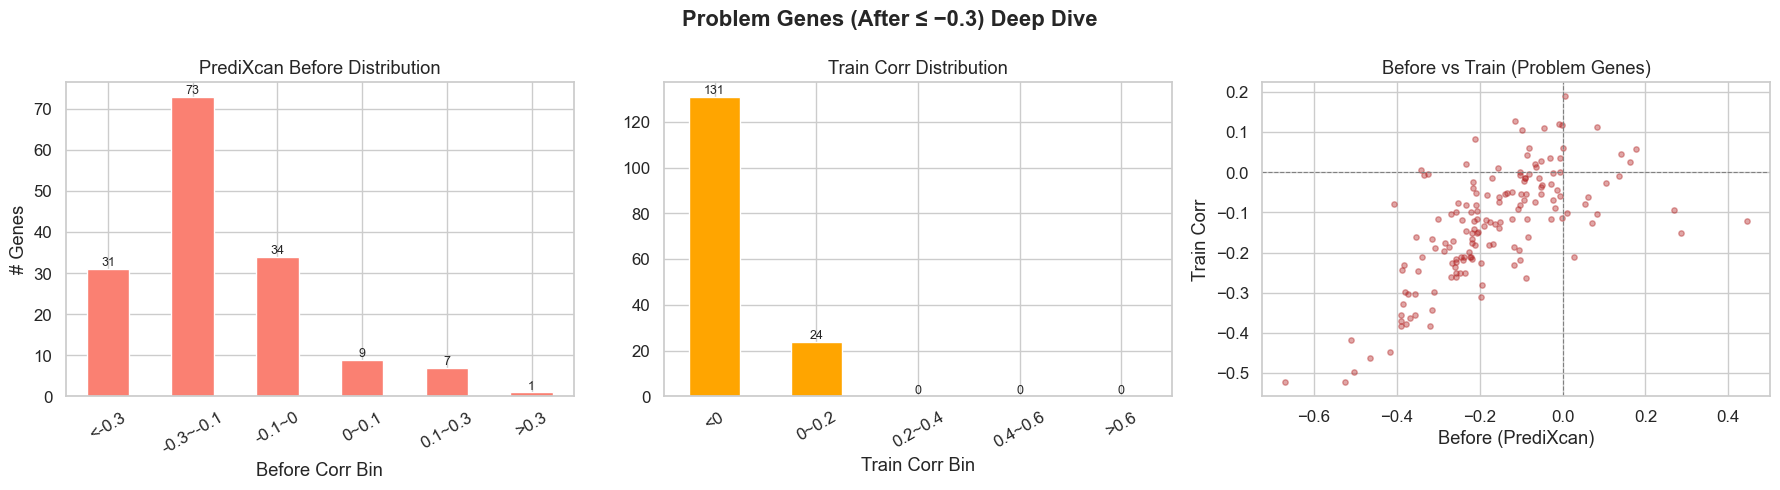

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Problem Genes (After ≤ −0.3) Deep Dive', fontweight='bold')

# Before 分布
neg['before_bin'].value_counts().reindex(b_labels).plot.bar(
    ax=axes[0], color='salmon', edgecolor='white')
axes[0].set_title('PrediXcan Before Distribution')
axes[0].set_xlabel('Before Corr Bin'); axes[0].set_ylabel('# Genes')
axes[0].tick_params(axis='x', rotation=30)
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=9)

# Train 分布
neg['train_bin'].value_counts().reindex(t_labels).plot.bar(
    ax=axes[1], color='orange', edgecolor='white')
axes[1].set_title('Train Corr Distribution')
axes[1].set_xlabel('Train Corr Bin')
axes[1].tick_params(axis='x', rotation=30)
for p in axes[1].patches:
    axes[1].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=9)

# Before vs Train scatter
axes[2].scatter(neg['before'], neg['train'], alpha=0.4, s=15, color='firebrick')
axes[2].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[2].axvline(0, color='gray', linestyle='--', linewidth=0.8)
axes[2].set_xlabel('Before (PrediXcan)'); axes[2].set_ylabel('Train Corr')
axes[2].set_title('Before vs Train (Problem Genes)')

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_07_neg_deep.png', dpi=150)
plt.show()

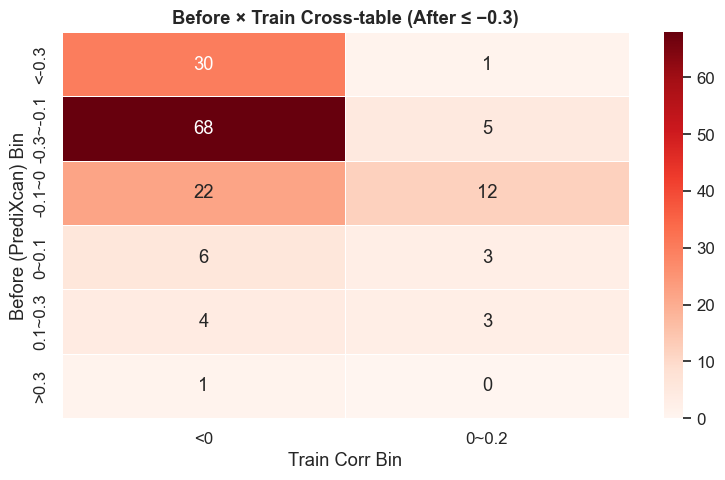

In [25]:
# Before x Train 交叉表 (heatmap)
ct = pd.crosstab(neg['before_bin'], neg['train_bin'])
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(ct, annot=True, fmt='d', cmap='Reds', linewidths=0.5, ax=ax)
ax.set_title('Before × Train Cross-table (After ≤ −0.3)', fontweight='bold')
ax.set_xlabel('Train Corr Bin'); ax.set_ylabel('Before (PrediXcan) Bin')
plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_08_crosstab.png', dpi=150)
plt.show()

## 8. Pre-filter 模擬：若 skip |baseline| < threshold

In [26]:
thresholds = [0.02, 0.03, 0.05, 0.08, 0.10, 0.15, 0.20]

rows = []
for thr in thresholds:
    skipped  = valid[valid['abs_baseline'] < thr]
    kept     = valid[valid['abs_baseline'] >= thr]
    lost_improved  = skipped[(skipped['after'] > 0) & (skipped['delta'] > 0.05)]
    avoided_neg    = skipped[skipped['after'] <= -0.1]
    avoided_worse  = skipped[skipped['delta'] < -0.05]
    rows.append({
        'threshold'      : thr,
        'n_skipped'      : len(skipped),
        'n_kept'         : len(kept),
        'lost_improved'  : len(lost_improved),
        'lost_improved_mean_after': lost_improved['after'].mean() if len(lost_improved) else 0,
        'avoided_neg'    : len(avoided_neg),
        'avoided_worse'  : len(avoided_worse),
    })

sim = pd.DataFrame(rows)
sim['net_benefit'] = sim['avoided_neg'] + sim['avoided_worse'] - sim['lost_improved']
sim.round(3)

,threshold,n_skipped,n_kept,lost_improved,lost_improved_mean_after,avoided_neg,avoided_worse,net_benefit
0,0.02,338,4444,117,0.142,66,98,47
1,0.03,514,4268,176,0.147,100,148,72
2,0.05,861,3921,303,0.145,166,260,123
3,0.08,1371,3411,488,0.145,251,416,179
4,0.10,1731,3051,582,0.146,334,531,283
5,0.15,2464,2318,772,0.156,501,764,493
6,0.20,3056,1726,890,0.165,628,958,696


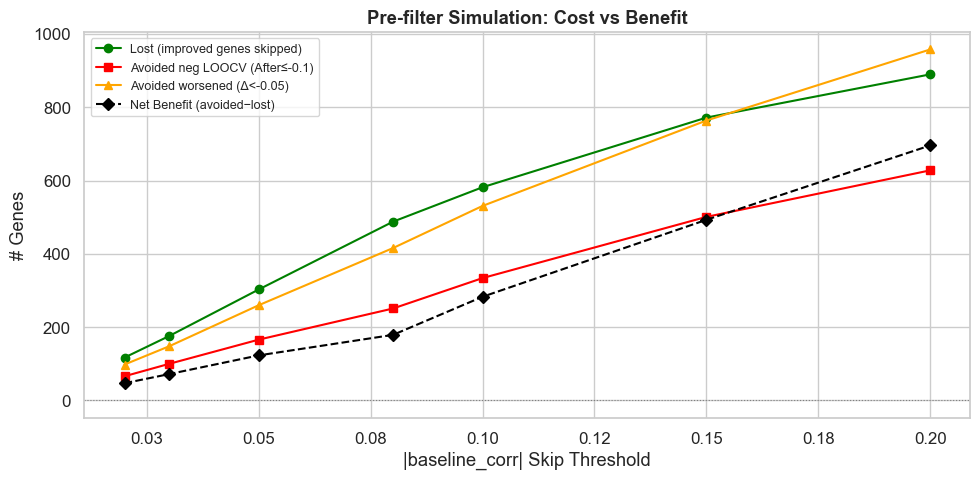

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sim['threshold'], sim['lost_improved'],  'o-', label='Lost (improved genes skipped)',  color='green')
ax.plot(sim['threshold'], sim['avoided_neg'],    's-', label='Avoided neg LOOCV (After≤-0.1)', color='red')
ax.plot(sim['threshold'], sim['avoided_worse'],  '^-', label='Avoided worsened (Δ<-0.05)',     color='orange')
ax.plot(sim['threshold'], sim['net_benefit'],    'D--',label='Net Benefit (avoided−lost)',      color='black', linewidth=1.5)
ax.axhline(0, color='gray', linewidth=0.8, linestyle=':')
ax.set_xlabel('|baseline_corr| Skip Threshold')
ax.set_ylabel('# Genes')
ax.set_title('Pre-filter Simulation: Cost vs Benefit', fontweight='bold')
ax.legend(fontsize=9)
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_09_prefilter_sim.png', dpi=150)
plt.show()

## 9. SNP 數對結果的影響

In [28]:
snp_bins   = [0, 5, 10, 15, 20, 30, 50, 999]
snp_labels = ['1-5','6-10','11-15','16-20','21-30','31-50','>50']
valid['snp_bin'] = pd.cut(valid['snp_tas'], bins=snp_bins, labels=snp_labels)

snp_seg = valid.groupby('snp_bin', observed=True).agg(
    n             = ('after',  'size'),
    after_mean    = ('after',  'mean'),
    after_median  = ('after',  'median'),
    train_mean    = ('train',  'mean'),
    gap_mean      = ('train_gap','mean'),
    pct_neg       = ('after',  lambda x: (x < 0).mean() * 100),
    pct_improved  = ('delta',  lambda x: (x >= 0.1).mean() * 100),
).round(3)
snp_seg

,n,after_mean,after_median,train_mean,gap_mean,pct_neg,pct_improved
snp_bin,,,,,,,
1-5,490,0.064,0.065,0.131,0.067,36.939,14.694
6-10,1708,0.082,0.079,0.161,0.079,33.958,15.515
11-15,1168,0.097,0.097,0.195,0.098,33.134,17.979
16-20,671,0.107,0.101,0.223,0.116,31.297,20.268
21-30,575,0.126,0.114,0.257,0.131,29.217,20.000
31-50,159,0.133,0.147,0.271,0.138,30.189,22.642
>50,11,0.165,0.173,0.337,0.172,9.091,9.091


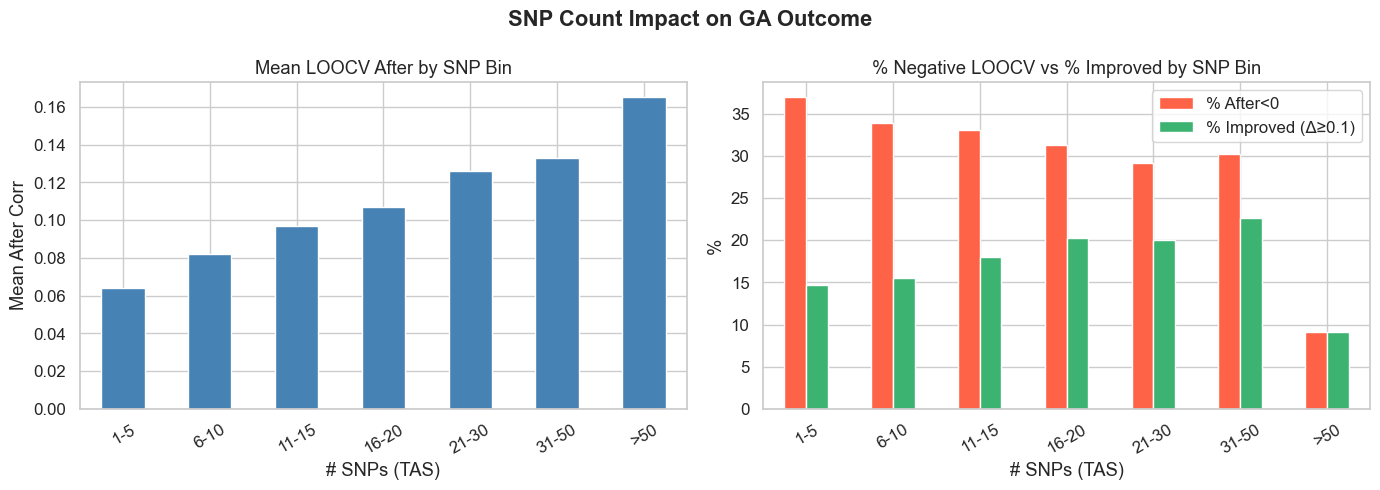

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('SNP Count Impact on GA Outcome', fontweight='bold')

snp_seg['after_mean'].plot.bar(ax=axes[0], color='steelblue', edgecolor='white')
axes[0].axhline(0, color='red', linewidth=0.8, linestyle='--')
axes[0].set_title('Mean LOOCV After by SNP Bin')
axes[0].set_xlabel('# SNPs (TAS)'); axes[0].set_ylabel('Mean After Corr')
axes[0].tick_params(axis='x', rotation=30)

snp_seg[['pct_neg','pct_improved']].plot.bar(ax=axes[1], color=['tomato','mediumseagreen'], edgecolor='white')
axes[1].set_title('% Negative LOOCV vs % Improved by SNP Bin')
axes[1].set_xlabel('# SNPs (TAS)'); axes[1].set_ylabel('%')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(['% After<0', '% Improved (Δ≥0.1)'])

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_10_snp_impact.png', dpi=150)
plt.show()

## 9b. SNP 數 × Baseline Tier 交叉分析

每個 SNP bin 在不同 baseline 強弱下，GA 能帶來多少改善？
- 橫軸：SNP 數分組 (TAS after-filter)
- 縱軸：Baseline corr 分群
- 值：mean(after_corr) 及 % improved (Δ ≥ 0.1)

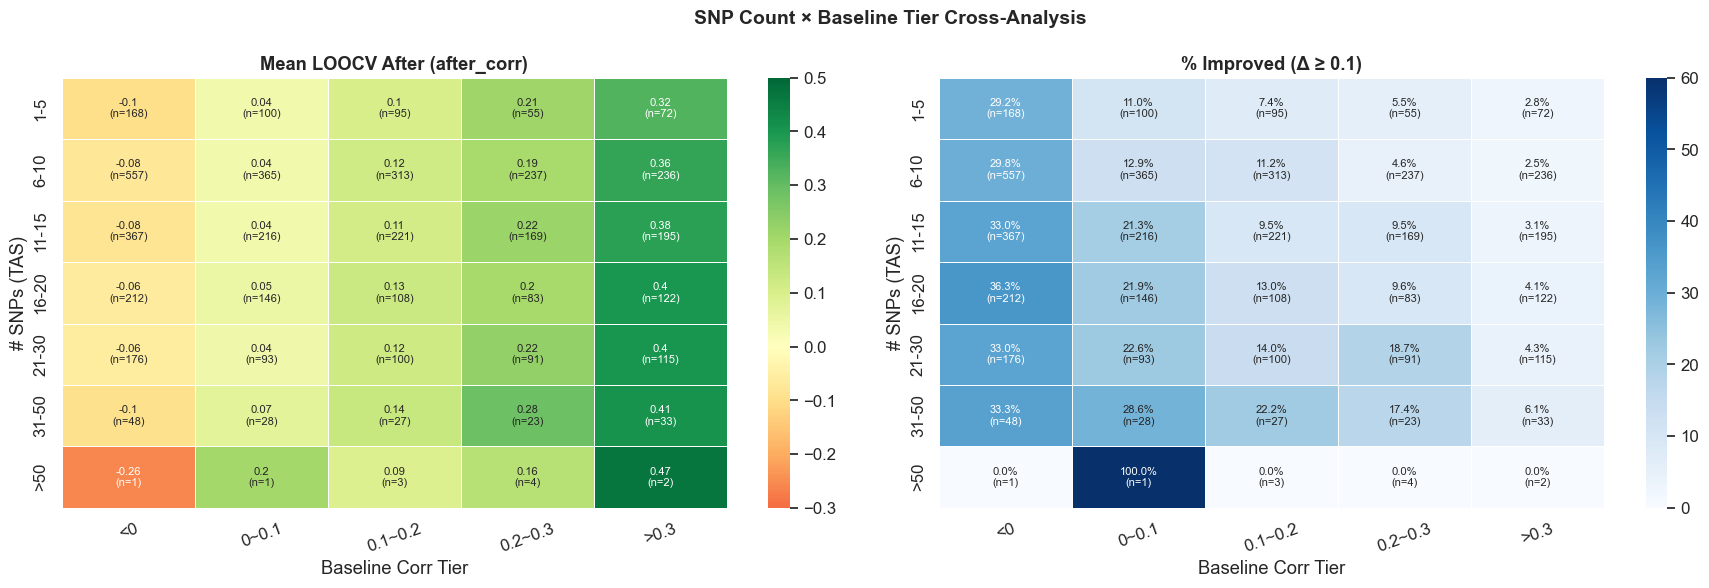

=== Mean After Corr (SNP Bin × Baseline Tier) ===


base_tier,<0,0~0.1,0.1~0.2,0.2~0.3,>0.3
snp_bin2,,,,,
1-5,-0.097,0.035,0.100,0.207,0.322
6-10,-0.075,0.038,0.117,0.191,0.365
11-15,-0.083,0.039,0.112,0.217,0.378
16-20,-0.064,0.049,0.128,0.195,0.398
21-30,-0.060,0.041,0.123,0.225,0.401
31-50,-0.095,0.072,0.135,0.285,0.407
>50,-0.259,0.202,0.093,0.164,0.470



=== % Improved (Δ≥0.1) by SNP Bin × Baseline Tier ===


base_tier,<0,0~0.1,0.1~0.2,0.2~0.3,>0.3
snp_bin2,,,,,
1-5,29.2,11.0,7.4,5.5,2.8
6-10,29.8,12.9,11.2,4.6,2.5
11-15,33.0,21.3,9.5,9.5,3.1
16-20,36.3,21.9,13.0,9.6,4.1
21-30,33.0,22.6,14.0,18.7,4.3
31-50,33.3,28.6,22.2,17.4,6.1
>50,0.0,100.0,0.0,0.0,0.0


In [30]:
# SNP bins × Baseline tier 交叉熱圖
base_bins   = [-1.01, 0.0, 0.10, 0.20, 0.30, 1.01]
base_labels = ['<0', '0~0.1', '0.1~0.2', '0.2~0.3', '>0.3']

v = valid.dropna(subset=['snp_tas', 'baseline_corr', 'after', 'delta']).copy()
v['snp_bin2']  = pd.cut(v['snp_tas'],       bins=snp_bins,  labels=snp_labels)
v['base_tier'] = pd.cut(v['baseline_corr'], bins=base_bins, labels=base_labels)

pivot_after = v.pivot_table(
    values='after', index='snp_bin2', columns='base_tier',
    aggfunc='mean', observed=True
).round(3)

pivot_impr = v.pivot_table(
    values='delta', index='snp_bin2', columns='base_tier',
    aggfunc=lambda x: (x >= 0.1).mean() * 100, observed=True
).round(1)

pivot_n = v.pivot_table(
    values='after', index='snp_bin2', columns='base_tier',
    aggfunc='count', observed=True
).fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('SNP Count × Baseline Tier Cross-Analysis', fontsize=14, fontweight='bold')

annot1 = pivot_after.round(2).astype(str) + '\n(n=' + pivot_n.astype(str) + ')'
sns.heatmap(pivot_after, annot=annot1, fmt='', cmap='RdYlGn', center=0,
            vmin=-0.3, vmax=0.5, linewidths=0.5, ax=axes[0],
            annot_kws={'size': 8})
axes[0].set_title('Mean LOOCV After (after_corr)', fontweight='bold')
axes[0].set_xlabel('Baseline Corr Tier')
axes[0].set_ylabel('# SNPs (TAS)')
axes[0].tick_params(axis='x', rotation=20)

annot2 = pivot_impr.round(1).astype(str) + '%\n(n=' + pivot_n.astype(str) + ')'
sns.heatmap(pivot_impr, annot=annot2, fmt='', cmap='Blues',
            vmin=0, vmax=60, linewidths=0.5, ax=axes[1],
            annot_kws={'size': 8})
axes[1].set_title('% Improved (Δ ≥ 0.1)', fontweight='bold')
axes[1].set_xlabel('Baseline Corr Tier')
axes[1].set_ylabel('# SNPs (TAS)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_12_snp_x_baseline_heatmap.png', dpi=150)
plt.show()

print("=== Mean After Corr (SNP Bin × Baseline Tier) ===")
display(pivot_after)
print("\n=== % Improved (Δ≥0.1) by SNP Bin × Baseline Tier ===")
display(pivot_impr)


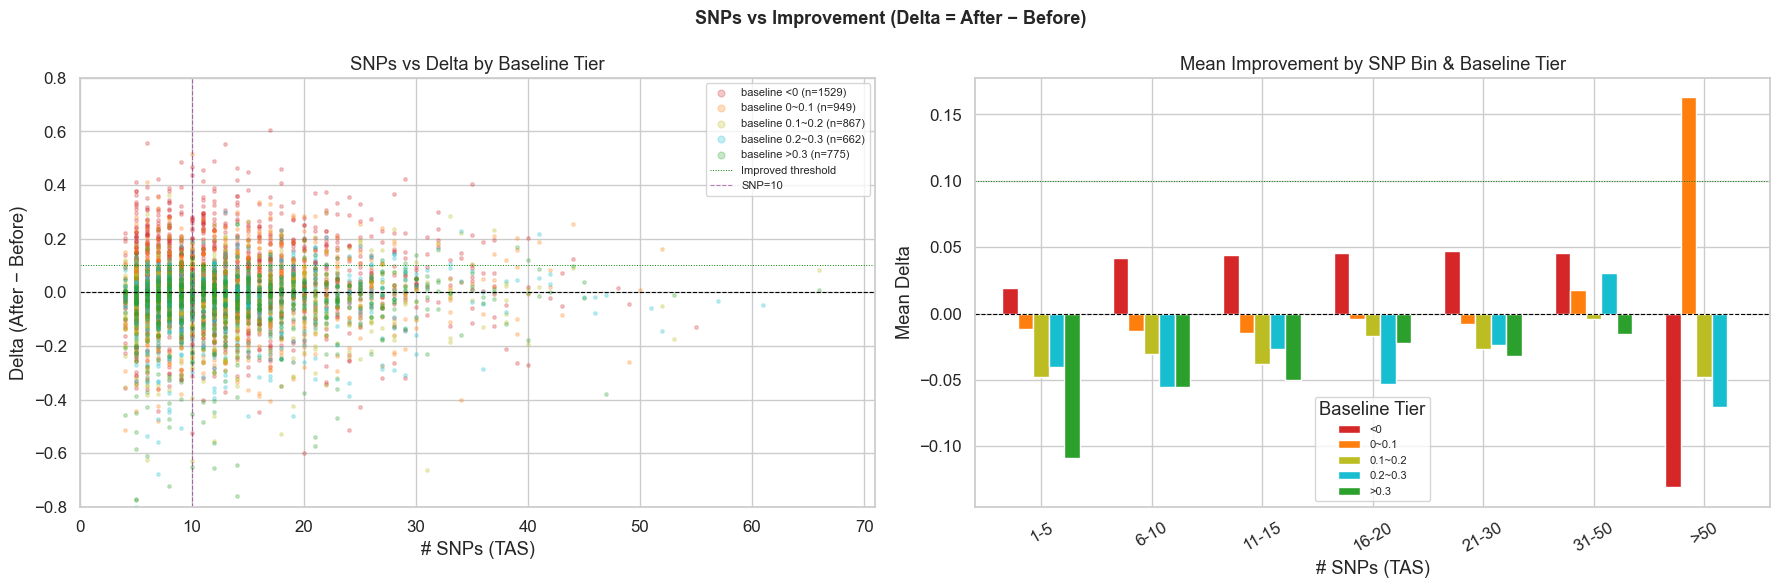

In [31]:
# SNP 數 vs Delta scatter，以 baseline tier 著色
palette_base = {
    '<0': '#d62728', '0~0.1': '#ff7f0e', '0.1~0.2': '#bcbd22',
    '0.2~0.3': '#17becf', '>0.3': '#2ca02c',
}

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('SNPs vs Improvement (Delta = After − Before)', fontsize=13, fontweight='bold')

# 左：scatter snp_tas vs delta，以 baseline tier 著色
for bt, grp in v.groupby('base_tier', observed=True):
    axes[0].scatter(grp['snp_tas'], grp['delta'],
                    alpha=0.25, s=6, color=palette_base.get(str(bt), 'gray'),
                    label=f'baseline {bt} (n={len(grp)})', rasterized=True)
axes[0].axhline(0,    color='black', linewidth=0.8, linestyle='--')
axes[0].axhline(0.1,  color='green', linewidth=0.7, linestyle=':', label='Improved threshold')
axes[0].axvline(10,   color='purple', linewidth=0.8, linestyle='--', alpha=0.5, label='SNP=10')
axes[0].set_xlabel('# SNPs (TAS)')
axes[0].set_ylabel('Delta (After − Before)')
axes[0].set_title('SNPs vs Delta by Baseline Tier')
axes[0].legend(fontsize=8, markerscale=2)
axes[0].set_xlim(0, min(v['snp_tas'].max() + 5, 120))
axes[0].set_ylim(-0.8, 0.8)

# 右：各 SNP bin 中，依 baseline tier 分群的 mean delta 橫條圖
delta_tbl = v.groupby(['snp_bin2', 'base_tier'], observed=True)['delta'].mean().unstack()
delta_tbl.plot.bar(
    ax=axes[1],
    color=[palette_base.get(str(c), 'gray') for c in delta_tbl.columns],
    edgecolor='white', width=0.7,
)
axes[1].axhline(0,   color='black', linewidth=0.8, linestyle='--')
axes[1].axhline(0.1, color='green', linewidth=0.7, linestyle=':')
axes[1].set_xlabel('# SNPs (TAS)')
axes[1].set_ylabel('Mean Delta')
axes[1].set_title('Mean Improvement by SNP Bin & Baseline Tier')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(title='Baseline Tier', fontsize=8)

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_13_snp_delta_scatter.png', dpi=150)
plt.show()


## 10. Sign-flip 啟用與否的差異

In [32]:
sf_seg = df_merged.groupby('sign_flip').agg(
    n              = ('after',              'size'),
    baseline_mean  = ('baseline_corr',      'mean'),
    after_mean     = ('after',              'mean'),
    train_mean     = ('train',              'mean'),
    gap_mean       = ('train_gap',          'mean'),
    pct_neg        = ('after',              lambda x: (x < 0).mean() * 100),
    pct_strong_neg = ('after',              lambda x: (x <= -0.3).mean() * 100),
    pct_improved   = ('delta',              lambda x: (x >= 0.1).mean() * 100),
    # MAE metrics from final_summary.csv
    mae_predixcan  = ('MAE_PrediXcan_Real', 'mean'),
    mae_ga         = ('MAE_GA_Real',        'mean'),
    mae_improve    = ('Improvement',        'mean'),
    weight_std_mean= ('weight_stability',   'mean'),
    train_std_mean = ('train_corr_std',     'mean'),
).round(3)
display(sf_seg)

,n,baseline_mean,after_mean,train_mean,gap_mean,pct_neg,pct_strong_neg,pct_improved,mae_predixcan,mae_ga,mae_improve,weight_std_mean,train_std_mean
sign_flip,,,,,,,,,,,,,
False,4782,0.103,0.094,0.191,0.096,32.936,3.241,17.461,5.831,9.79,-0.008,0.139,0.024


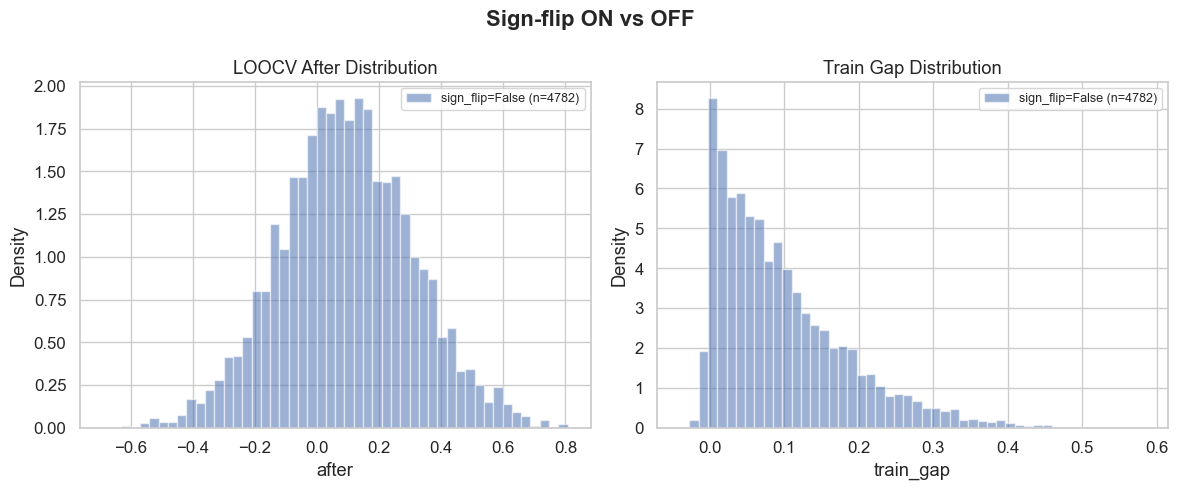

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Sign-flip ON vs OFF', fontweight='bold')

for ax, col, title in zip(axes,
    ['after', 'train_gap'],
    ['LOOCV After Distribution', 'Train Gap Distribution']):
    for sf_val, grp in valid.groupby('sign_flip'):
        label = f'sign_flip={sf_val} (n={len(grp)})'
        ax.hist(grp[col].dropna(), bins=50, alpha=0.55, density=True, label=label)
    ax.set_title(title); ax.set_xlabel(col); ax.set_ylabel('Density')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_11_signflip.png', dpi=150)
plt.show()

## 11. D4 & D5 — Weight Stability & Fold Variance Analysis (Discussion)

- **D4**: `weight_stability`（各 run 間 weight 的標準差）與 LOOCV 表現的關係  
- **D5**: `train_corr_std`（各 fold train corr 的方差）能否作為 LOOCV 失效的早期預警

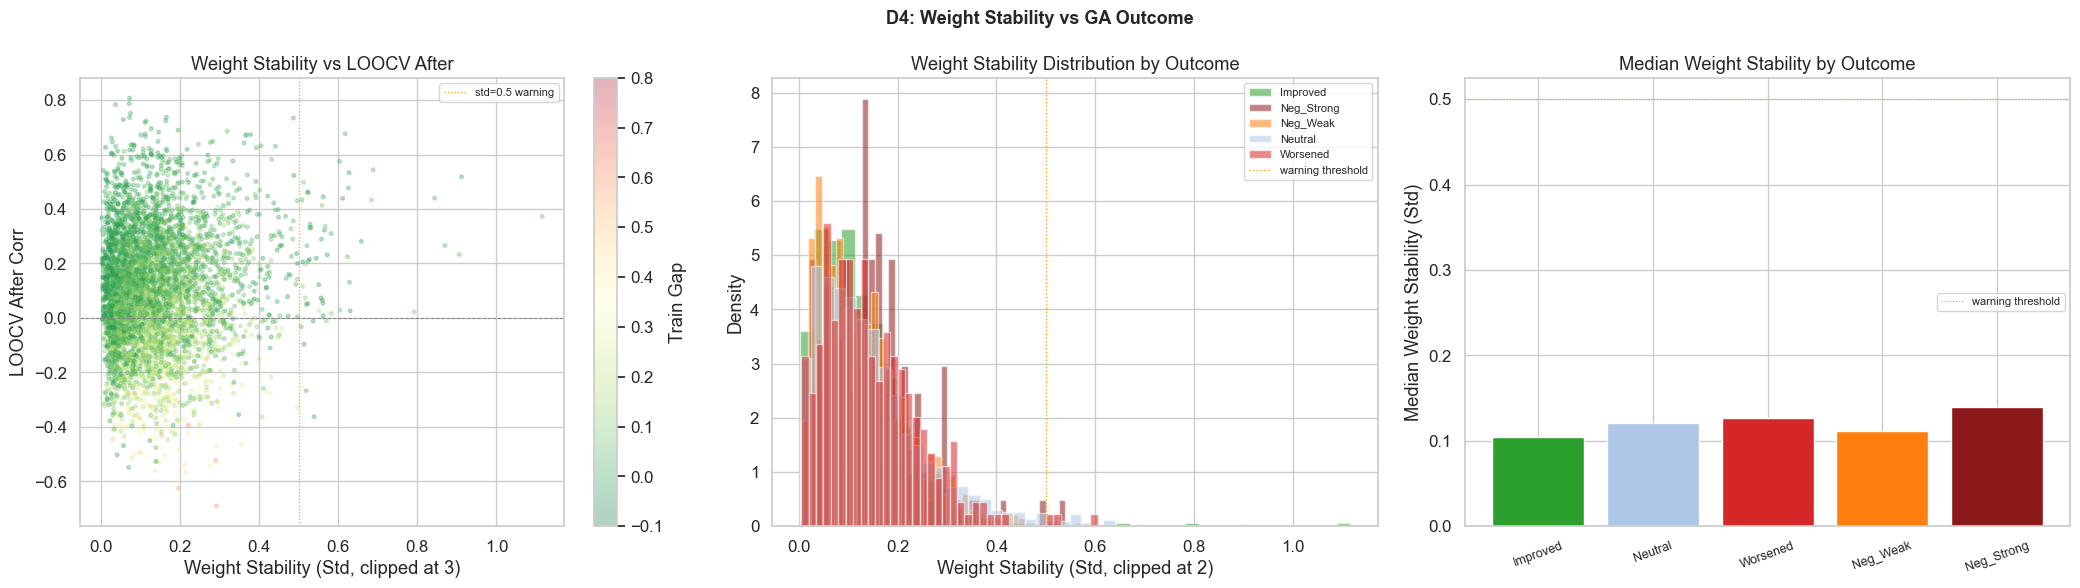

,n,ws_mean,ws_median,pct_high
outcome,,,,
Improved,708,0.121,0.105,0.565
Neg_Strong,153,0.144,0.139,0.654
Neg_Weak,1422,0.129,0.111,0.422
Neutral,2201,0.149,0.121,1.908
Worsened,298,0.146,0.127,1.007


In [34]:
# D4: weight_stability vs LOOCV After Corr, by outcome
m_d4 = df_merged.dropna(subset=['weight_stability', 'after'])

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
fig.suptitle('D4: Weight Stability vs GA Outcome', fontsize=13, fontweight='bold')

sc = axes[0].scatter(m_d4['weight_stability'].clip(upper=3), m_d4['after'],
                     c=m_d4['train_gap'], cmap='RdYlGn_r',
                     vmin=-0.1, vmax=0.8, alpha=0.3, s=7, rasterized=True)
plt.colorbar(sc, ax=axes[0], label='Train Gap')
axes[0].axhline(0, color='gray', linewidth=0.7, linestyle='--')
axes[0].axvline(0.5, color='orange', linewidth=0.9, linestyle=':', label='std=0.5 warning')
axes[0].set_xlabel('Weight Stability (Std, clipped at 3)')
axes[0].set_ylabel('LOOCV After Corr')
axes[0].set_title('Weight Stability vs LOOCV After')
axes[0].legend(fontsize=8)

for oc_name, grp in m_d4.groupby('outcome'):
    axes[1].hist(grp['weight_stability'].clip(0, 2), bins=40, alpha=0.55,
                 density=True, color=color_map.get(oc_name, 'gray'), label=oc_name)
axes[1].axvline(0.5, color='orange', linewidth=1, linestyle=':', label='warning threshold')
axes[1].set_xlabel('Weight Stability (Std, clipped at 2)')
axes[1].set_ylabel('Density')
axes[1].set_title('Weight Stability Distribution by Outcome')
axes[1].legend(fontsize=8)

ws_by_out = m_d4.groupby('outcome')['weight_stability'].median().reindex(
    ['Improved', 'Neutral', 'Worsened', 'Neg_Weak', 'Neg_Strong']).dropna()
axes[2].bar(range(len(ws_by_out)), ws_by_out.values,
            color=[color_map.get(k, 'gray') for k in ws_by_out.index], edgecolor='white')
axes[2].set_xticks(range(len(ws_by_out)))
axes[2].set_xticklabels(ws_by_out.index, rotation=20, fontsize=9)
axes[2].set_ylabel('Median Weight Stability (Std)')
axes[2].set_title('Median Weight Stability by Outcome')
axes[2].axhline(0.5, color='orange', linewidth=0.8, linestyle=':', label='warning threshold')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_D4_weight_stability.png', dpi=150)
plt.show()

ws_table = m_d4.groupby('outcome').agg(
    n=('weight_stability', 'size'),
    ws_mean=('weight_stability', 'mean'),
    ws_median=('weight_stability', 'median'),
    pct_high=('weight_stability', lambda x: (x > 0.5).mean() * 100),
).round(3)
display(ws_table)

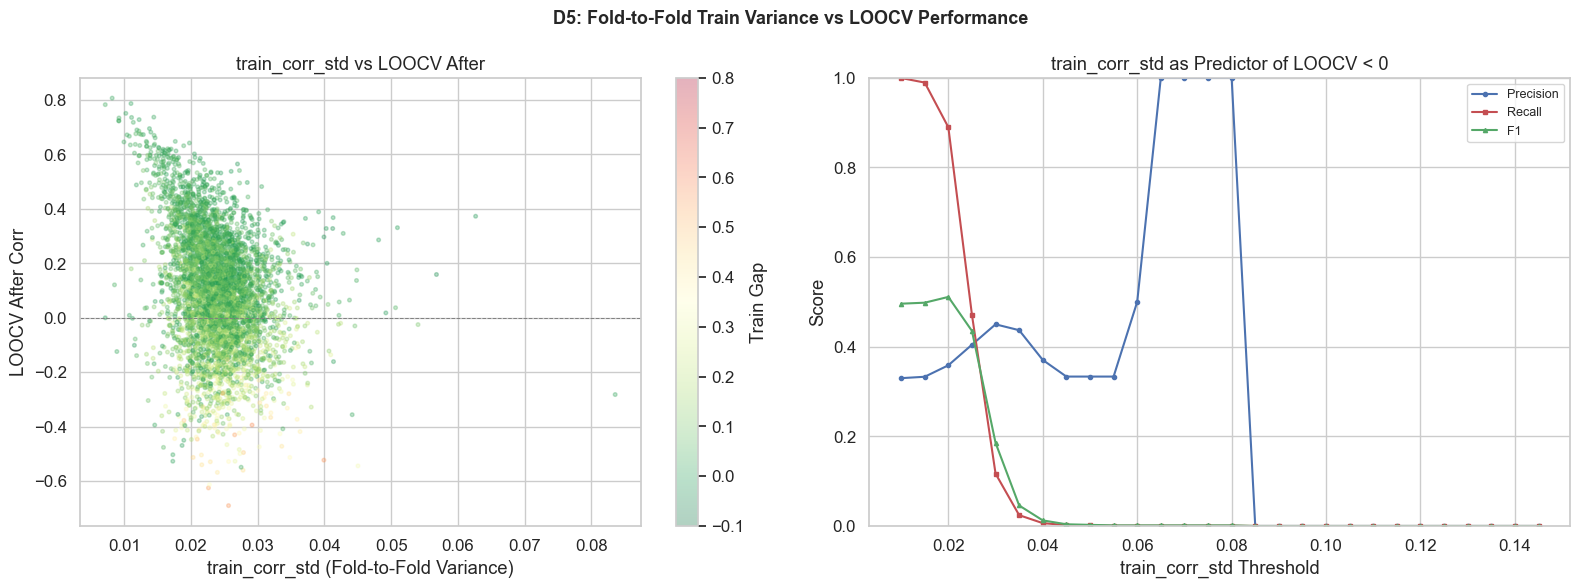

Best F1 at std threshold=0.020: Precision=0.358, Recall=0.890, F1=0.511


In [35]:
# D5: train_corr_std as predictor of LOOCV failure
m_d5 = df_merged.dropna(subset=['train_corr_std', 'after'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('D5: Fold-to-Fold Train Variance vs LOOCV Performance', fontsize=13, fontweight='bold')

sc5 = axes[0].scatter(m_d5['train_corr_std'], m_d5['after'],
                      c=m_d5['train_gap'], cmap='RdYlGn_r',
                      vmin=-0.1, vmax=0.8, alpha=0.3, s=7, rasterized=True)
plt.colorbar(sc5, ax=axes[0], label='Train Gap')
axes[0].axhline(0, color='gray', linewidth=0.7, linestyle='--')
axes[0].set_xlabel('train_corr_std (Fold-to-Fold Variance)')
axes[0].set_ylabel('LOOCV After Corr')
axes[0].set_title('train_corr_std vs LOOCV After')

thresholds_std = np.arange(0.01, 0.15, 0.005)
rows_d5 = []
for thr in thresholds_std:
    flagged     = m_d5[m_d5['train_corr_std'] > thr]
    not_flagged = m_d5[m_d5['train_corr_std'] <= thr]
    tp = (flagged['after'] < 0).sum()
    fp = (flagged['after'] >= 0).sum()
    fn = (not_flagged['after'] < 0).sum()
    precision = tp / max(tp + fp, 1)
    recall    = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-6)
    rows_d5.append({'thr': thr, 'n_flagged': len(flagged), 'precision': precision,
                    'recall': recall, 'f1': f1})

sim_d5 = pd.DataFrame(rows_d5)
axes[1].plot(sim_d5['thr'], sim_d5['precision'], 'b-o', markersize=3, label='Precision')
axes[1].plot(sim_d5['thr'], sim_d5['recall'],    'r-s', markersize=3, label='Recall')
axes[1].plot(sim_d5['thr'], sim_d5['f1'],        'g-^', markersize=3, label='F1')
axes[1].set_xlabel('train_corr_std Threshold')
axes[1].set_ylabel('Score')
axes[1].set_title('train_corr_std as Predictor of LOOCV < 0')
axes[1].legend(fontsize=9)
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig(LOG_PATH.parent / 'fig_D5_fold_variance.png', dpi=150)
plt.show()

best = sim_d5.loc[sim_d5['f1'].idxmax()]
print(f"Best F1 at std threshold={best['thr']:.3f}: "
      f"Precision={best['precision']:.3f}, Recall={best['recall']:.3f}, F1={best['f1']:.3f}")

## §4.1.2  LOOCV without Sign Flip — Overview

§4.1.2 Global Metrics: {'total_genes': 5884, 'reliable': np.int64(3033), 'unreliable': np.int64(2851), 'neg_after': np.int64(1576), 'global_corr': np.float64(0.0945), 'avg_delta': np.float64(-0.008), 'avg_train_gap': np.float64(0.0963)}


,before,after,train,delta,train_gap,MAE_PrediXcan_Real,MAE_GA_Real,Improvement,weight_stability
count,4782.0000,4782.0000,4782.0000,4782.0000,4782.0000,4782.0000,4782.0000,4782.0000,4782.0000
mean,0.1024,0.0945,0.1907,-0.0080,0.0963,5.8310,9.7897,-0.0080,0.1387
std,0.2034,0.2146,0.1872,0.1411,0.0886,184.3882,364.9687,0.1411,0.1061
min,-0.6699,-0.6897,-0.5228,-0.8840,-0.0396,0.5372,0.5063,-0.8840,0.0024
25%,-0.0378,-0.0473,0.0652,-0.0759,0.0274,1.0309,1.0281,-0.0759,0.0612
50%,0.0913,0.0906,0.1830,-0.0019,0.0739,1.1252,1.1284,-0.0019,0.1164
75%,0.2317,0.2385,0.3153,0.0659,0.1411,1.2103,1.2199,0.0659,0.1849
max,0.7987,0.8067,0.8201,0.6036,0.5841,10442.8359,22251.7129,0.6036,1.1156


,count,avg_improvement,pct
Impact_Category,,,
Moderate Improvement (0.3~0.6),72,0.3726,1.22
No Impact (-0.1~0.1),3023,-0.0002,51.38
Significant Improvement (> 0.6),1,0.6036,0.02
Slight Improvement (0.1~0.3),761,0.1707,12.93
Worsened (< -0.1),925,-0.2106,15.72


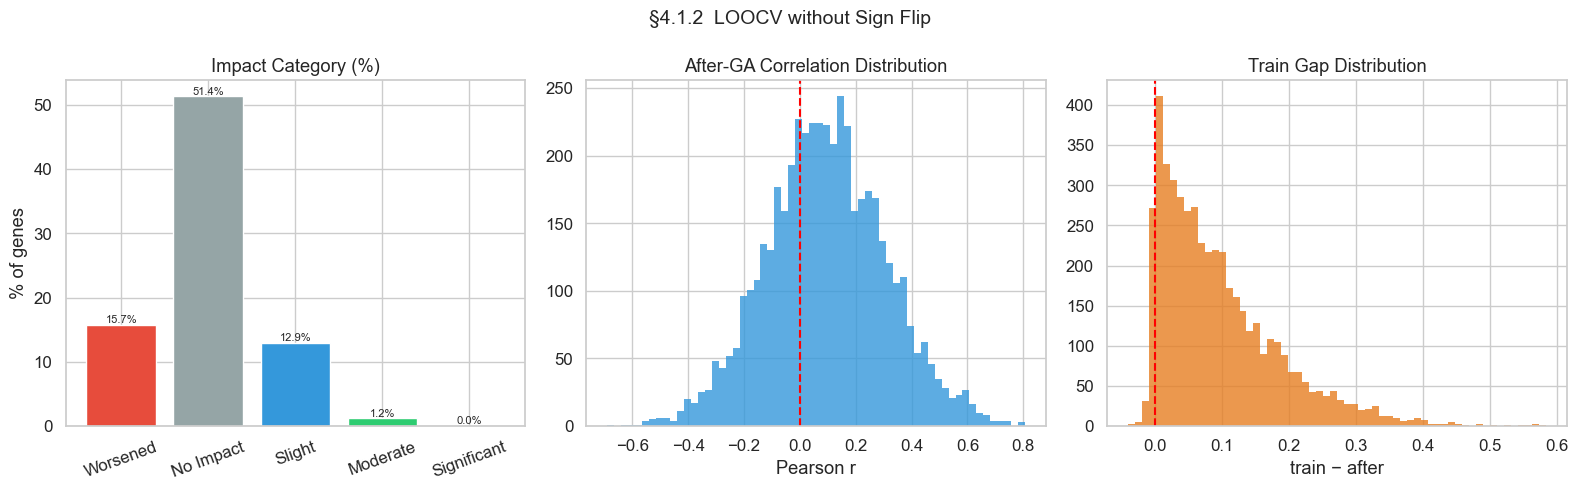

In [36]:
# ── §4.1.2: LOOCV without Sign Flip ──────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

UNSIGN_CSV = Path(r"D:\GA - 複製\LOOCV_Unsign\final_summary.csv")
UNSIGN_OUT = UNSIGN_CSV.parent / "figures"
UNSIGN_OUT.mkdir(exist_ok=True)

df_us = pd.read_csv(UNSIGN_CSV).rename(columns={
    "Correlation before GA": "before",
    "Correlation after GA":  "after",
    "train_corr":            "train",
})
df_us["delta"]     = df_us["after"] - df_us["before"]
df_us["train_gap"] = df_us["train"] - df_us["after"]

# Global metrics
total    = len(df_us)
reliable = (df_us["before"].abs() >= 0.1).sum()
neg_corr = (df_us["after"] < 0).sum()
global_stats = dict(
    total_genes   = total,
    reliable      = reliable,
    unreliable    = total - reliable,
    neg_after     = neg_corr,
    global_corr   = df_us["after"].mean().round(4),
    avg_delta     = df_us["delta"].mean().round(4),
    avg_train_gap = df_us["train_gap"].mean().round(4),
)
print("§4.1.2 Global Metrics:", global_stats)

# Descriptive stats
desc_cols = ["before","after","train","delta","train_gap",
             "MAE_PrediXcan_Real","MAE_GA_Real","Improvement","weight_stability"]
display(df_us[desc_cols].describe().round(4))

# Impact_Category table
ic = df_us.groupby("Impact_Category").agg(
    count=("gene_id","count"),
    avg_improvement=("Improvement","mean"),
).assign(pct=lambda d: (d["count"]/total*100).round(2))
display(ic.round(4))

# Figure: Impact_Category bar + corr hist + train_gap hist
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("§4.1.2  LOOCV without Sign Flip", fontsize=14)

order = ["Worsened (< -0.1)","No Impact (-0.1~0.1)",
         "Slight Improvement (0.1~0.3)","Moderate Improvement (0.3~0.6)",
         "Significant Improvement (> 0.6)"]
pcts = [ic.loc[o,"pct"] if o in ic.index else 0 for o in order]
short = ["Worsened","No Impact","Slight","Moderate","Significant"]
colors = ["#e74c3c","#95a5a6","#3498db","#2ecc71","#27ae60"]
axes[0].bar(short, pcts, color=colors)
axes[0].set_title("Impact Category (%)")
axes[0].set_ylabel("% of genes")
axes[0].tick_params(axis="x", rotation=20)
for i,(h,c) in enumerate(zip(pcts,short)):
    axes[0].text(i, h+0.3, f"{h:.1f}%", ha="center", fontsize=8)

axes[1].hist(df_us["after"].dropna(), bins=60, color="#3498db", edgecolor="none", alpha=0.8)
axes[1].axvline(0, color="red", lw=1.5, ls="--")
axes[1].set_title("After-GA Correlation Distribution")
axes[1].set_xlabel("Pearson r")

axes[2].hist(df_us["train_gap"].dropna().clip(-1,1), bins=60,
             color="#e67e22", edgecolor="none", alpha=0.8)
axes[2].axvline(0, color="red", lw=1.5, ls="--")
axes[2].set_title("Train Gap Distribution")
axes[2].set_xlabel("train − after")

plt.tight_layout()
plt.savefig(UNSIGN_OUT / "fig_4_1_2_overview.png", dpi=150, bbox_inches="tight")
plt.show()


## 12. 匯出分析結果

In [37]:
'''
out_csv = LOG_PATH.parent / 'log_parsed.csv'
df.to_csv(out_csv, index=False)
print(f'Saved: {out_csv}')
df[df['after'].notna()].head()
'''

"\nout_csv = LOG_PATH.parent / 'log_parsed.csv'\ndf.to_csv(out_csv, index=False)\nprint(f'Saved: {out_csv}')\ndf[df['after'].notna()].head()\n"

## §4.3  Sign Flip vs No-Sign-Flip (LOOCV)

label,Sign,Unsign
total,4782.0000,5884.0000
reliable,3041.0000,3033.0000
unreliable,1741.0000,2851.0000
neg_after,1575.0000,1576.0000
global_corr,0.0945,0.0945
avg_delta,-0.0080,-0.0080
avg_train_gap,0.0963,0.0963
avg_mae_pred,5.8310,5.8310
avg_mae_ga,9.7897,9.7897
avg_improve,-0.0080,-0.0080


NameError: name 'pathlib' is not defined

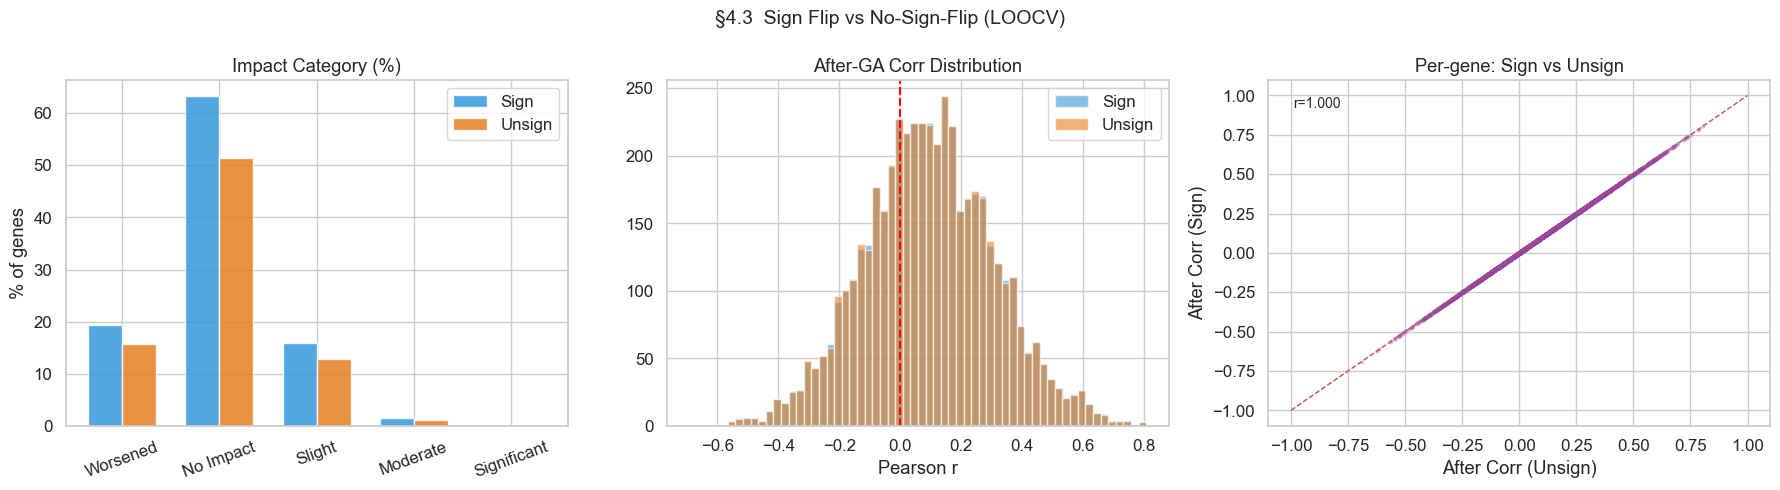

In [38]:
# ── §4.3: Sign vs Unsign comparison (LOOCV) ─────────────────────
# Requires df_merged (Sign) from §1.5 and df_us (Unsign) from §4.1.2

def run_metrics(df, label):
    total    = len(df)
    reliable = (df["before"].abs() >= 0.1).sum()
    order = ["Worsened (< -0.1)","No Impact (-0.1~0.1)",
             "Slight Improvement (0.1~0.3)","Moderate Improvement (0.3~0.6)",
             "Significant Improvement (> 0.6)"]
    ic_pct = {o: (df["Impact_Category"]==o).mean()*100 for o in order}
    return dict(
        label         = label,
        total         = total,
        reliable      = reliable,
        unreliable    = total - reliable,
        neg_after     = (df["after"] < 0).sum(),
        global_corr   = df["after"].mean().round(4),
        avg_delta     = df["delta"].mean().round(4),
        avg_train_gap = df["train_gap"].mean().round(4),
        avg_mae_pred  = df["MAE_PrediXcan_Real"].mean().round(4),
        avg_mae_ga    = df["MAE_GA_Real"].mean().round(4),
        avg_improve   = df["Improvement"].mean().round(4),
        worsened_pct  = round(ic_pct["Worsened (< -0.1)"], 2),
        no_impact_pct = round(ic_pct["No Impact (-0.1~0.1)"], 2),
        improved_pct  = round(ic_pct.get("Slight Improvement (0.1~0.3)",0)
                              + ic_pct.get("Moderate Improvement (0.3~0.6)",0)
                              + ic_pct.get("Significant Improvement (> 0.6)",0), 2),
    )

# Sign uses df_merged; align column names
df_sign = df_merged.copy()
if "before" not in df_sign.columns:
    df_sign = df_sign.rename(columns={"csv_before":"before","csv_after":"after","csv_train":"train"})
if "delta" not in df_sign.columns:
    df_sign["delta"]     = df_sign["after"] - df_sign["before"]
    df_sign["train_gap"] = df_sign["train"] - df_sign["after"]

m_sign  = run_metrics(df_sign, "Sign")
m_unsign = run_metrics(df_us,  "Unsign")
metrics_df = pd.DataFrame([m_sign, m_unsign]).set_index("label").T
display(metrics_df)

# Figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("§4.3  Sign Flip vs No-Sign-Flip (LOOCV)", fontsize=14)

order_short = ["Worsened","No Impact","Slight","Moderate","Significant"]
order_full  = ["Worsened (< -0.1)","No Impact (-0.1~0.1)",
               "Slight Improvement (0.1~0.3)","Moderate Improvement (0.3~0.6)",
               "Significant Improvement (> 0.6)"]
colors_sign   = ["#e74c3c","#95a5a6","#3498db","#2ecc71","#27ae60"]
colors_unsign = ["#c0392b","#7f8c8d","#2980b9","#27ae60","#1e8449"]

x = np.arange(len(order_short))
w = 0.35
pct_s = [(df_sign["Impact_Category"]==o).mean()*100 for o in order_full]
pct_u = [(df_us["Impact_Category"]==o).mean()*100 for o in order_full]
axes[0].bar(x-w/2, pct_s, w, label="Sign",   color="#3498db", alpha=0.85)
axes[0].bar(x+w/2, pct_u, w, label="Unsign", color="#e67e22", alpha=0.85)
axes[0].set_title("Impact Category (%)")
axes[0].set_xticks(x); axes[0].set_xticklabels(order_short, rotation=20)
axes[0].set_ylabel("% of genes"); axes[0].legend()

axes[1].hist(df_sign["after"].dropna(), bins=60, alpha=0.6, label="Sign",   color="#3498db")
axes[1].hist(df_us["after"].dropna(),   bins=60, alpha=0.6, label="Unsign", color="#e67e22")
axes[1].axvline(0, color="red", lw=1.5, ls="--")
axes[1].set_title("After-GA Corr Distribution")
axes[1].set_xlabel("Pearson r"); axes[1].legend()

# Per-gene scatter (merge on gene_id)
common = df_sign[["gene","after"]].merge(
    df_us[["gene_id","after"]].rename(columns={"gene_id":"gene","after":"after_us"}),
    on="gene", how="inner")
axes[2].scatter(common["after_us"], common["after"], alpha=0.2, s=5, color="#8e44ad")
axes[2].plot([-1,1],[-1,1],"r--",lw=1)
axes[2].set_xlabel("After Corr (Unsign)"); axes[2].set_ylabel("After Corr (Sign)")
axes[2].set_title("Per-gene: Sign vs Unsign")
from scipy.stats import pearsonr
r,p = pearsonr(common["after_us"], common["after"])
axes[2].text(0.05,0.92,f"r={r:.3f}", transform=axes[2].transAxes, fontsize=10)

plt.tight_layout()
out_dir = pathlib.Path(r"D:\GA - 複製\figures")
out_dir.mkdir(exist_ok=True)
plt.savefig(out_dir / "fig_4_3_sign_vs_unsign.png", dpi=150, bbox_inches="tight")
plt.show()

# Paired stats
common_delta = df_sign[["gene","delta"]].merge(
    df_us[["gene_id","delta"]].rename(columns={"gene_id":"gene","delta":"delta_us"}),
    on="gene", how="inner")
print(f"Sign avg delta:   {common_delta['delta'].mean():.4f}")
print(f"Unsign avg delta: {common_delta['delta_us'].mean():.4f}")
mae_diff_sign   = (df_sign["MAE_PrediXcan_Real"] - df_sign["MAE_GA_Real"]).mean()
mae_diff_unsign = (df_us["MAE_PrediXcan_Real"]   - df_us["MAE_GA_Real"]).mean()
print(f"Sign MAE reduction:   {mae_diff_sign:.4f}")
print(f"Unsign MAE reduction: {mae_diff_unsign:.4f}")


## §4.4  Cross-Validation Strategy Comparison (LOOCV vs 10-Fold vs 3-Fold)

In [ ]:
# ── §4.4: CV method comparison ───────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pathlib
from scipy.stats import pearsonr

CV_DIRS = {
    "LOOCV":   pathlib.Path(r"D:\GA - 複製\LOOCV_Sign"),
    "10-Fold": pathlib.Path(r"D:\GA - 複製\10Fold_Sign"),
    "3-Fold":  pathlib.Path(r"D:\GA - 複製\3Fold_Sign"),
}

dfs_44 = {}
for name, d in CV_DIRS.items():
    df = pd.read_csv(d / "final_summary.csv").rename(columns={
        "Correlation before GA": "before",
        "Correlation after GA":  "after",
        "train_corr":            "train",
    })
    df["delta"]     = df["after"] - df["before"]
    df["train_gap"] = df["train"] - df["after"]
    dfs_44[name] = df

# ── Global metrics table
ORDER_FULL = ["Worsened (< -0.1)","No Impact (-0.1~0.1)",
              "Slight Improvement (0.1~0.3)","Moderate Improvement (0.3~0.6)",
              "Significant Improvement (> 0.6)"]
rows = []
for name, df in dfs_44.items():
    total = len(df)
    ic_pcts = {o:(df["Impact_Category"]==o).mean()*100 for o in ORDER_FULL}
    # read overall_performance_metrics.txt for time and global corr
    perf_path = CV_DIRS[name] / "overall_performance_metrics.txt"
    perf = {}
    if perf_path.exists():
        for line in perf_path.read_text().splitlines():
            if ":" in line:
                k,v = line.split(":",1)
                perf[k.strip()] = v.strip()
    rows.append(dict(
        Method        = name,
        Total         = total,
        Unreliable    = (df["before"].abs()<0.1).sum(),
        Neg_After     = (df["after"]<0).sum(),
        Global_Corr   = df["after"].mean().round(4),
        Avg_Delta     = df["delta"].mean().round(4),
        Avg_TrainGap  = df["train_gap"].mean().round(4),
        MAE_Pred      = df["MAE_PrediXcan_Real"].mean().round(4),
        MAE_GA        = df["MAE_GA_Real"].mean().round(4),
        Avg_Improve   = df["Improvement"].mean().round(4),
        Weight_Std    = df["weight_stability"].mean().round(4),
        Compute_s     = perf.get("Avg Time Per Gene","N/A"),
        Worsened_pct  = round(ic_pcts["Worsened (< -0.1)"],2),
        NoImpact_pct  = round(ic_pcts["No Impact (-0.1~0.1)"],2),
        Improved_pct  = round(sum(ic_pcts[o] for o in ORDER_FULL[2:]),2),
    ))

summary_44 = pd.DataFrame(rows).set_index("Method")
display(summary_44.T)

out_dir = pathlib.Path(r"D:\GA - 複製\figures")
out_dir.mkdir(exist_ok=True)

# ── Figure 1: Impact Category % bar + After Corr boxplot
ORDER_SHORT = ["Worsened","No Impact","Slight","Moderate","Significant"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("§4.4  CV Method Comparison", fontsize=14)

x = np.arange(len(ORDER_SHORT))
w = 0.25
palette = ["#3498db","#e67e22","#2ecc71"]
for i,(name,df) in enumerate(dfs_44.items()):
    pcts = [(df["Impact_Category"]==o).mean()*100 for o in ORDER_FULL]
    axes[0].bar(x + (i-1)*w, pcts, w, label=name, color=palette[i], alpha=0.85)
axes[0].set_title("Impact Category (%)")
axes[0].set_xticks(x); axes[0].set_xticklabels(ORDER_SHORT, rotation=15)
axes[0].set_ylabel("% of genes"); axes[0].legend()

data_box  = [df["after"].dropna().values for df in dfs_44.values()]
bp = axes[1].boxplot(data_box, labels=list(dfs_44.keys()), patch_artist=True,
                     medianprops=dict(color="black",lw=2))
for patch,col in zip(bp["boxes"], palette):
    patch.set_facecolor(col); patch.set_alpha(0.7)
axes[1].axhline(0, color="red", ls="--", lw=1.5)
axes[1].set_title("After-GA Correlation")
axes[1].set_ylabel("Pearson r")
plt.tight_layout()
plt.savefig(out_dir / "fig_4_4_cv_impact_corr.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Figure 2: MAE violin + per-gene scatter vs LOOCV
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

mae_data = [df["Improvement"].dropna().values for df in dfs_44.values()]
vp = axes[0].violinplot(mae_data, showmedians=True)
for body,col in zip(vp["bodies"], palette):
    body.set_facecolor(col); body.set_alpha(0.7)
axes[0].set_xticks([1,2,3]); axes[0].set_xticklabels(list(dfs_44.keys()))
axes[0].axhline(0, color="red", ls="--", lw=1.5)
axes[0].set_title("MAE Improvement Distribution")
axes[0].set_ylabel("MAE_PrediXcan − MAE_GA")

loocv_df = dfs_44["LOOCV"].rename(columns={"gene_id":"gene"})
for i,(name,df) in enumerate(list(dfs_44.items())[1:]):
    merged = loocv_df[["gene","after"]].merge(
        df[["gene_id","after"]].rename(columns={"gene_id":"gene","after":f"after_{name}"}),
        on="gene", how="inner")
    r,p = pearsonr(merged["after"], merged[f"after_{name}"])
    axes[1].scatter(merged["after"], merged[f"after_{name}"],
                    alpha=0.2, s=4, label=f"{name} (r={r:.3f})", color=palette[i+1])
axes[1].plot([-1,1],[-1,1],"r--",lw=1)
axes[1].set_xlabel("After Corr (LOOCV)")
axes[1].set_ylabel("After Corr (k-Fold)")
axes[1].set_title("Per-gene Agreement vs LOOCV")
axes[1].legend()
plt.tight_layout()
plt.savefig(out_dir / "fig_4_4_mae_vs_loocv.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Figure 3: Weight stability + compute time
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ws_data = [df["weight_stability"].dropna().values for df in dfs_44.values()]
bp2 = axes[0].boxplot(ws_data, labels=list(dfs_44.keys()), patch_artist=True,
                      medianprops=dict(color="black",lw=2))
for patch,col in zip(bp2["boxes"], palette):
    patch.set_facecolor(col); patch.set_alpha(0.7)
axes[0].set_title("Weight Stability (lower = more stable)")
axes[0].set_ylabel("Weight Std")

ct_data = [df["compute_time"].dropna().values for df in dfs_44.values()]
bp3 = axes[1].boxplot(ct_data, labels=list(dfs_44.keys()), patch_artist=True,
                      medianprops=dict(color="black",lw=2))
for patch,col in zip(bp3["boxes"], palette):
    patch.set_facecolor(col); patch.set_alpha(0.7)
axes[1].set_title("Compute Time per Gene (s)")
axes[1].set_ylabel("Seconds")
plt.tight_layout()
plt.savefig(out_dir / "fig_4_4_stability_time.png", dpi=150, bbox_inches="tight")
plt.show()

# Pearson r between LOOCV and each k-fold
for name in ["10-Fold","3-Fold"]:
    merged = loocv_df[["gene","after"]].merge(
        dfs_44[name][["gene_id","after"]].rename(columns={"gene_id":"gene","after":f"after_{name}"}),
        on="gene", how="inner")
    r,p = pearsonr(merged["after"], merged[f"after_{name}"])
    print(f"LOOCV vs {name}: r={r:.4f}, p={p:.2e}, n={len(merged)}")


## 4.5. GSE33356 vs Simulation Comparison

*(Results pending)*

**預計比較指標：**
- Correlation improvement rate（真實 vs 模擬）
- Impact_Category 分布
- Overfitting pattern（train_gap 分布）

In [ ]:
# TODO: Load simulation results
# SIM_PATH = Path(r"...\GA_Simulation\final_summary.csv")
# df_sim = pd.read_csv(SIM_PATH)
#
# Compare real GSE33356 vs simulation
# Key question: does GA improve more in simulation (simpler distributions)?
pass